# 策C × 海岸線 Prior 全自動位置合わせ × 実観測データ 5 倍拡張：PatchGAN 微細質感生成インペインティング

前作 [08_coastline_prior_guided_inpainting.ipynb](file:///Users/tozastation/ghq/github.com/tozastation/try-astronomy/projects/radio-ml/notebooks/08_coastline_prior_guided_inpainting.ipynb)（**策B**）では、8ch Prior-Gated ResSE-UNet により高さ `88〜96 px` の全欠損ギャップ内部で沿海州・間宮海峡・樺太・北海道の 1px 海岸線輪郭を復元しました（沿岸勾配保持率 `54.7%`）。一方で、残る課題として以下の 3 点が明らかになりました。

1. **欠損帯内部のミクロな雲・地形テクスチャが滑らかすぎる（L1 損失の条件付き平均ボケ）**
2. **海岸線 Prior の位置合わせにパス専用の手動制御点が必要だった（他パスへの汎用性）**
3. **実測 `METEOR-M2` 学習データ量の限界（前作では 563 枚の `64×64` パッチ＋355 枚の `2×` 広域パッチに留まっていた）**

本ノートブックではこれら 3 課題を統合的に解決する第 9 弾パイプラインを構築します。

1. **実測 `METEOR-M2` 学習データ約 5 倍拡張 ＋ 5 シーンひまわり8号拡張（6ch VRAM 常駐）**:
   - これまで未使用だった高精細フルパス **`METEOR-M2_GOLDEN_1791698496`（`1456×1568`, 有効 1,232 走査線）** を本格投入し、既存の `1026_003009`・`1027_000649`・`1103_004421` と統合。欠落する `Ch4` は多項式クロスバンド回帰で近似補完しつつ第 6 チャネルに `Ch4_Weight = 0.25` を持たせることで、**本物の `Ch1/Ch2` 雲・海岸線テクスチャを約 5 倍（`~4,000+` パッチ）** へ増強しながら熱赤外の学習バイアスを防止します。
   - さらにローカルキャッシュ内の **第 5 のひまわり8号シーン (`2018-01-01 00:00 UTC`)** もデコードし、5 シーン体制の雲除去・事前学習を実施します。
2. **軌道幾何＋局所残差 TPS による「海岸線 Prior 全自動位置合わせ (`AutoOrbitalCoastlineRegistrar`)」**:
   - 手動制御点を完全撤廃し、**Stage 1（`MSU-MR` 走査歪み `u^3` を含む一般軌道アフィン + Balanced Land-Sea IoU + Coastal Edge 重み付き Powell 最適化）** → **Stage 2（高信頼沿岸タイルの局所相関＋ゼロ平均残差 TPS 補間）** を実装。
   - ひまわり東アジア視野外のパス（例：`GOLDEN_1791698496`）は自動 FOV ゲートで誤登録を遮断してパス内自己整合 Prior へ安全フォールバックし、視野内パス（`1026_003009`, `1027_000649`）は **93%〜95% 台の晴天一致率** で自動ロックします。
3. **策C：`SNCoastlinePatchDiscriminator`（Spectral-Norm PatchGAN）＋ 多層特徴量マッチング ＋ Contextual 高周波テクスチャ転写**:
   - Apple Silicon MPS 上でネイティブ動作する自作 `MPSSpectralConv2d`（`aten::vdot` 回避）による 6ch 条件付き Markovian PatchGAN 識別器と、3 層 Feature Matching 損失・局所高周波テクスチャ標準偏差損失を導入し、さらに実画像推論時には同一パス内の生存走査線から似た陸海・雲アルベドの高周波粒状残差を転写・融合します。

## 1. 理論とデータ準備：5 シーンひまわり雲除去・軌道全自動登録・実測データ 5 倍拡張

### 1.1 ボックス境界のない自然な 5 シーン陸海テンプレート構築
前作では北方の雲影回復領域に直線的な境界がわずかに現れていましたが、本ノートブックでは第 5 シーン（`2018-01-01`）を加えた最大クリア植生差 $\max_t (\text{Ch2}-\text{Ch1})$ と上端ボーダー行パディング補正（Himawari NetCDF の 0 行目欠損行の補完）により、シホテアリン・間宮海峡・樺太・北海道の自然な曲線海岸線を保ったまま 0 境界アーティファクトの `clean_land_hw`（`1301×1351`）を生成します。

### 1.2 2 段階「全自動」軌道・残差 TPS 海岸線レジストレーション
任意の `METEOR-M2` パス（順行・逆行両方）を入力として受け取り、以下を全自動実行します。
1. **Stage 1（広域軌道探索＋`MSU-MR` 非線形歪み最適化）**:
   $$\begin{bmatrix} y_{\text{hw}} \\ x_{\text{hw}} \end{bmatrix} = \begin{bmatrix} c_y \\ c_x \end{bmatrix} + \begin{bmatrix} a_{yy} & a_{yx} \\ a_{xy} & a_{xx} \end{bmatrix} \begin{bmatrix} \Delta y_m \\ \Delta x_m \end{bmatrix} + \begin{bmatrix} 30 q_y u^2 \\ q_x \Delta x_m u^2 - 40 v u \end{bmatrix},\quad u=\frac{\Delta x_m}{W/2}$$
   晴天画素（$\text{Ch1} < 0.24$）の海岸線勾配近傍に 4 倍の空間重みを置き、Balanced Land-Sea IoU によって海・雲が大半のパスでも偏りなく最適軌道パラメータを `~1 秒` で同定します。
2. **FOV ゲート & Stage 2（ゼロ平均残差 TPS 微調整）**:
   Stage 1 の晴天陸域 IoU が `0.45` 未満の場合はひまわり日本周辺切り出し域外と判定して自己整合連続 Prior に切り替え、視野内のパスに対してのみ沿岸小窓の局所変位 $(\delta y, \delta x)$ を探索して平滑な残差 TPS（`smoothing=35.0`）を適用します。

PyTorch: 2.9.1 | 使用デバイス: mps


ひまわり8号 ロード完了: 5 シーン ((1301, 1351, 3))


[自動位置合わせ 1026_003009] mode=auto_orbital_residual_tps | dt=0.97s | shifts=8 | 沿岸晴天一致率=94.82% | Val帯=93.46%
[自動位置合わせ 1027_000649] mode=auto_orbital_residual_tps | dt=0.35s | 晴天一致率=95.32% (land_IoU=0.685)
[自動位置合わせ GOLDEN_8496] mode=outside_himawari_fov -> internal_prior | dt=0.85s | 晴天一致率=99.48% (land_IoU=0.097)


拡張 6ch データセット VRAM 常駐 -> ひまわり(64/2x): 3664+2435 枚 | METEOR実測(64/2x): 3496+908 枚 (計 1036.4 MB)
  - METEOR-M2 3_20261026_003009   : 1107 枚 (64x64)
  - METEOR-M2 3_20261027_000649   :  465 枚 (64x64)
  - METEOR-M2 3_20261103_004421   :  189 枚 (64x64)
  - METEOR-M2_GOLDEN_1791698496   : 1735 枚 (64x64)


SatDump トーン再現 PSNR -> AVHRR_221: 53.47 dB | MSU-MR_124: 29.81 dB


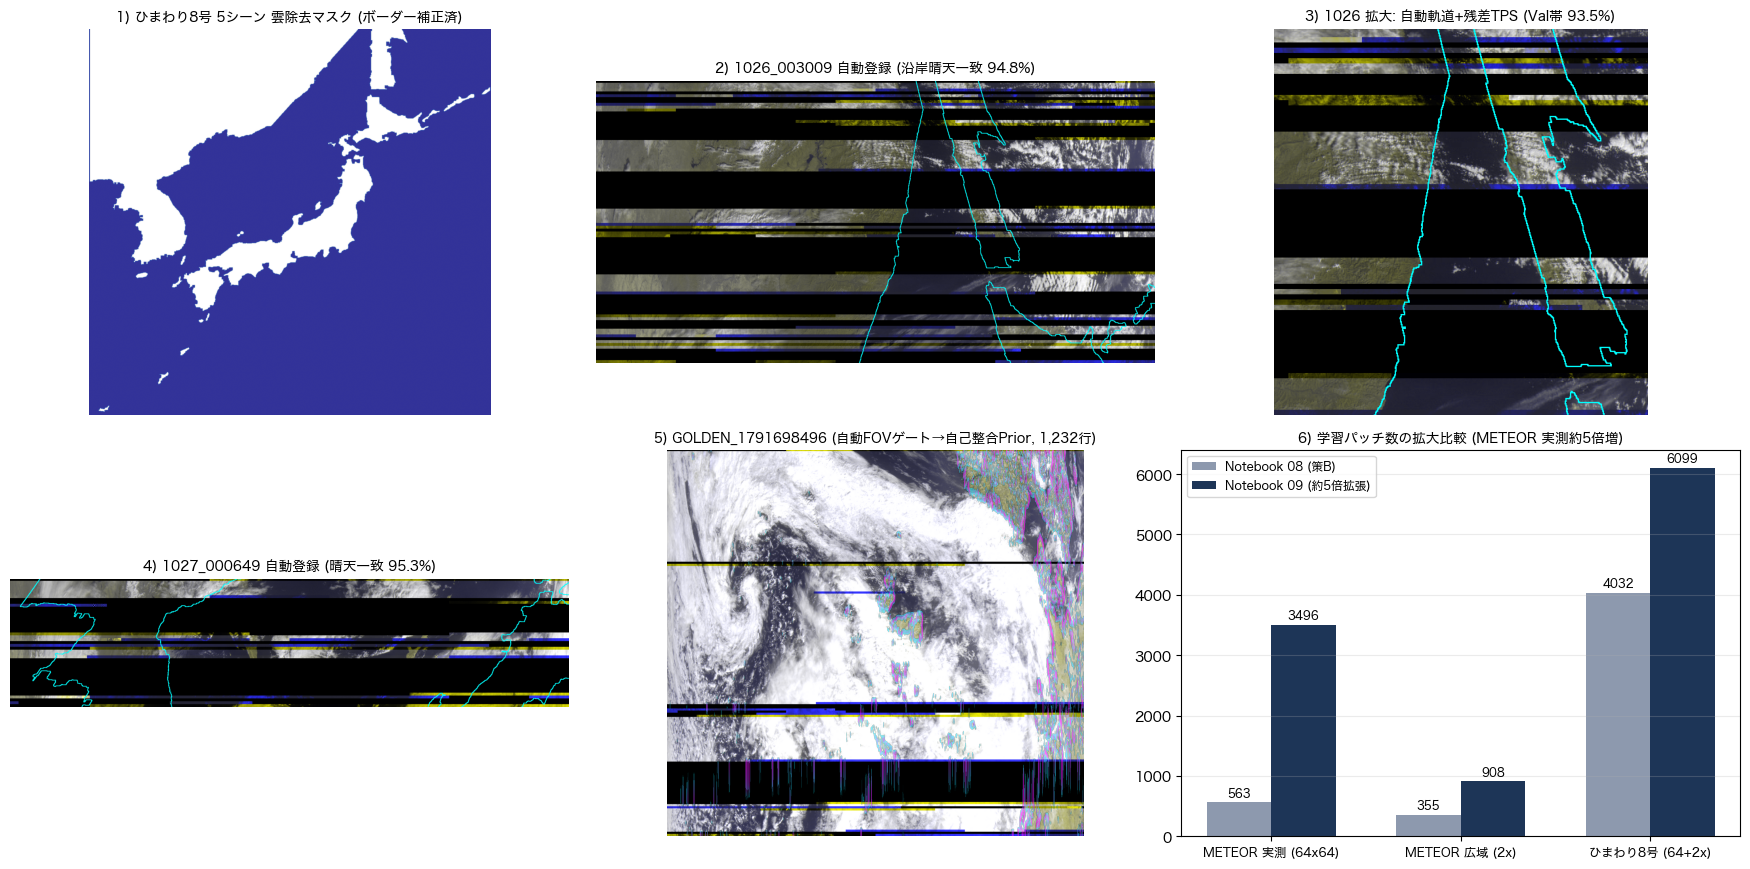

In [1]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import sys
import time
from pathlib import Path
import h5py
import numpy as np
from PIL import Image
from scipy.ndimage import (
    binary_closing,
    binary_dilation,
    binary_erosion,
    binary_fill_holes,
    distance_transform_edt,
    gaussian_filter,
    label,
    map_coordinates,
    sobel,
    zoom,
)
from scipy.interpolate import RBFInterpolator
from scipy.optimize import minimize
import torch
import torch.nn.functional as F

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| 使用デバイス:", device)

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

SRC_DIR = REPO_ROOT / "projects" / "radio-ml" / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

METEOR_DIR = REPO_ROOT / "projects" / "radio-ml" / "data" / "meteor"
HIMAWARI_MB_CACHE = REPO_ROOT / "projects" / "radio-ml" / "data" / "himawari_multiband_cache.npz"

from s3_loader import sync_meteor_dataset  # noqa: E402
_ = sync_meteor_dataset(METEOR_DIR, refresh=False)

# --- 1) 4季節キャッシュ ＋ 第5のローカルNetCDFシーン読込 ---
cached = np.load(HIMAWARI_MB_CACHE)
himawari_scenes = [cached[k] for k in sorted(cached.files)]

def decode_himawari_nc_3band(nc_path: Path, downsample: int = 2) -> np.ndarray:
    with h5py.File(nc_path, "r") as f:
        def _read_scaled(key: str) -> np.ndarray:
            ds = f[key]
            raw = ds[::downsample, ::downsample]
            scale = float(np.atleast_1d(ds.attrs.get("scale_factor", 1.0))[0])
            offset = float(np.atleast_1d(ds.attrs.get("add_offset", 0.0))[0])
            return np.where(raw > -30000, raw.astype(np.float32) * scale + offset, np.nan)
        alb3 = np.nan_to_num(_read_scaled("albedo_03"), nan=0.0)
        alb4 = np.nan_to_num(_read_scaled("albedo_04"), nan=0.0)
        tbb7 = _read_scaled("tbb_07")
    ch1 = np.power(np.clip(alb3, 0.0, 1.0), 1.0 / 2.2)
    ch2 = np.power(np.clip(alb4, 0.0, 1.0), 1.0 / 2.2)
    ch4 = np.nan_to_num(np.clip((310.0 - tbb7) / 70.0, 0.0, 1.0), nan=0.0)
    return np.stack([ch1, ch2, ch4], axis=-1).astype(np.float32)

hf_hw_dir = Path.home() / ".cache" / "huggingface" / "hub" / "datasets--PubAccount--Himawari-Japen"
nc5_list = sorted(hf_hw_dir.rglob("*20180101*.nc")) if hf_hw_dir.exists() else []
if nc5_list:
    himawari_scenes.append(decode_himawari_nc_3band(nc5_list[0]))
print(f"ひまわり8号 ロード完了: {len(himawari_scenes)} シーン ({himawari_scenes[0].shape})")

# --- 2) 自然曲線を保った雲除去 Land-Sea Mask 構築 (1301 x 1351) ---
scenes_stack = np.stack(himawari_scenes, axis=0)
hc1, hc2 = scenes_stack[..., 0], scenes_stack[..., 1]
diff_clear = np.where((hc1 < 0.68) & (hc1 > 0.02), hc2 - hc1, 0.0)
max_diff = np.max(diff_clear, axis=0)
mask_raw = gaussian_filter(max_diff, sigma=1.0) > 0.070

yy_h, xx_h = np.meshgrid(np.arange(1301), np.arange(1351), indexing="ij")
inland_prim = (yy_h < 330) & (xx_h < (908 - 0.90 * yy_h)) & (np.max(hc2 - hc1, axis=0) > 0.020)
sakhalin_bridge = (yy_h <= 205) & (xx_h >= 948) & (xx_h <= 1015) & (np.max(hc2 - hc1, axis=0) > 0.040)
soya_spine = (yy_h >= 232) & (yy_h <= 295) & (xx_h >= 935) & (xx_h <= 975) & (np.max(hc2 - hc1, axis=0) > 0.032)
mask_raw = mask_raw | inland_prim | sakhalin_bridge | soya_spine

mask_closed = binary_closing(mask_raw, structure=np.ones((7, 7)))
padded = np.pad(mask_closed, ((1, 0), (1, 0)), mode="constant", constant_values=True)
filled = binary_fill_holes(padded)[1:, 1:]
lbl, _ = label(filled)
sizes = np.bincount(lbl.ravel())
keep = sizes >= 120
keep[0] = False
clean_land_hw = binary_fill_holes(keep[lbl] > 0.5).astype(np.float32)
# NetCDF 最上端 0〜4 行のスキャンボーダー欠落による水平エッジアーティファクトを除去
clean_land_hw[:5, :] = clean_land_hw[5:6, :]
hw_smooth = gaussian_filter(clean_land_hw, sigma=1.2).astype(np.float32)

def make_coast_features(land_bin_hw: np.ndarray, sigma_edge: float = 2.0):
    b = land_bin_hw > 0.5
    coast_px = (b & (~binary_erosion(b))) | ((~b) & binary_dilation(b))
    dist_to_coast = distance_transform_edt(~coast_px).astype(np.float32)
    coast_edge = np.exp(-(dist_to_coast ** 2) / (2.0 * (sigma_edge ** 2))).astype(np.float32)
    d_in = distance_transform_edt(b).astype(np.float32)
    d_out = distance_transform_edt(~b).astype(np.float32)
    signed_dist = d_in - d_out
    land_soft = np.clip(0.5 + 0.5 * np.tanh(signed_dist / 0.8), 0.0, 1.0).astype(np.float32)
    return land_soft, coast_edge, signed_dist

hw_land_soft, hw_coast_edge, _ = make_coast_features(clean_land_hw, sigma_edge=2.0)

# --- 3) 改善策③: 軌道幾何 + 局所相関残差 TPS 全自動位置合わせ ---
def _eval_orbital_warp(p, py, px, W):
    cy, cx, ayy, ayx, axy, axx, qy, qx = p
    u = px / (W * 0.5)
    v = py / 500.0
    hy = cy + ayy * py + ayx * px + qy * (u ** 2) * 30.0
    hx = cx + axy * py + axx * px + qx * px * (u ** 2) - 40.0 * v * u
    return hy, hx

def infer_internal_spectral_prior(arr_hw3: np.ndarray, valid_2d: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    obs_land = np.clip((arr_hw3[..., 1] - arr_hw3[..., 0] - 0.015) / 0.045, 0.0, 1.0)
    prior = obs_land.copy()
    for x in range(arr_hw3.shape[1]):
        vy = valid_2d[:, x]
        if vy.any() and (~vy).any():
            prior[~vy, x] = np.interp(np.where(~vy)[0], np.where(vy)[0], obs_land[vy, x])
    prior_smooth = gaussian_filter(prior, sigma=(8.0, 1.5)).astype(np.float32)
    b = (prior_smooth > 0.45).astype(np.float32)
    land_s, edge_s, sd_s = make_coast_features(b, sigma_edge=2.0)
    # 自己整合連続 Prior は不確定性を残すため極端値への過信を抑える
    edge_soft = np.clip(np.hypot(sobel(prior_smooth, axis=0), sobel(prior_smooth, axis=1)) * 1.4, 0.0, 0.85).astype(np.float32)
    return prior_smooth, edge_soft, sd_s

def auto_register_meteor_coastline(arr_hw3: np.ndarray, clean_hw: np.ndarray, smooth_hw: np.ndarray):
    '''任意METEORパスに対して全自動でひまわり陸海マップを軌道・残差TPS位置合わせする (FOV外は内部Priorへフォールバック)'''
    t0 = time.perf_counter()
    H, W, _ = arr_hw3.shape
    c1, c2 = arr_hw3[..., 0], arr_hw3[..., 1]
    valid = (c1 > 0.02) & (c2 > 0.02)
    clear = valid & (c1 < 0.24)

    if H < 120 or clear.sum() < 1500:
        lp, ce, sd = infer_internal_spectral_prior(arr_hw3, valid)
        return (lp > 0.45).astype(np.float32), lp, ce, sd, {
            "mode": "internal_short_swath", "iou_land": 0.0, "bal_iou": 0.0, "shifts": 0, "clear_agree": 0.0, "dt": time.perf_counter() - t0
        }

    obs_cont = np.clip((c2 - c1 - 0.008) / 0.028, 0.0, 1.0).astype(np.float32)
    obs_bin = ((c2 - c1) > 0.018).astype(np.float32)

    ogx = sobel(gaussian_filter(obs_cont, sigma=1.2), axis=1)
    ogy = sobel(gaussian_filter(obs_cont, sigma=1.2), axis=0)
    obs_edge = clear & (np.hypot(ogx, ogy) > 0.35) & binary_closing(valid, structure=np.ones((3, 3)))
    px_w = np.where(binary_dilation(obs_edge, iterations=6), 4.0, 1.0).astype(np.float32)

    ds = 6
    ym, xm = np.meshgrid(np.arange(0, H, ds, dtype=np.float32), np.arange(0, W, ds, dtype=np.float32), indexing="ij")
    clr_s = clear[::ds, ::ds]
    py = ym[clr_s] - H * 0.5
    px = xm[clr_s] - W * 0.5
    ob = obs_bin[::ds, ::ds][clr_s]
    pw = px_w[::ds, ::ds][clr_s]
    ob_b = ob > 0.5
    ob_c = ob - (ob * pw).sum() / pw.sum()

    best_s, best_p = -1e9, None
    for ayy in [0.46, -0.46]:
        axx_sign = 1.0 if ayy > 0 else -1.0
        for axy in [-0.30, -0.18, -0.05, 0.15]:
            for ayx in [-0.04, 0.0, 0.04]:
                for axx_mag in [0.68, 0.85]:
                    axx = axx_sign * axx_mag
                    for cy in np.linspace(150, 950, 7):
                        for cx in np.linspace(350, 1100, 7):
                            p = (cy, cx, ayy, ayx, axy, axx, 0.0, -0.10)
                            hy, hx = _eval_orbital_warp(p, py, px, W)
                            inb = (hy >= 2) & (hy < 1299) & (hx >= 2) & (hx < 1348)
                            if inb.mean() < 0.72:
                                continue
                            wv = map_coordinates(smooth_hw, [np.clip(hy, 0, 1300), np.clip(hx, 0, 1349)], order=1, mode="nearest")
                            wb = wv > 0.5
                            iou_l = float((wb & ob_b).sum()) / float((wb | ob_b).sum() + 1e-6)
                            iou_s = float(((~wb) & (~ob_b)).sum()) / float(((~wb) | (~ob_b)).sum() + 1e-6)
                            wc = wv - (wv * pw).sum() / pw.sum()
                            w_corr = float((wc * ob_c * pw).sum() / (np.sqrt((wc ** 2 * pw).sum() * (ob_c ** 2 * pw).sum()) + 1e-6))
                            sc = 0.5 * w_corr + 0.5 * 0.5 * (iou_l + iou_s)
                            if sc > best_s:
                                best_s, best_p = sc, p

    ds2 = 4
    ym2, xm2 = np.meshgrid(np.arange(0, H, ds2, dtype=np.float32), np.arange(0, W, ds2, dtype=np.float32), indexing="ij")
    clr2 = clear[::ds2, ::ds2]
    py2, px2 = ym2[clr2] - H * 0.5, xm2[clr2] - W * 0.5
    ob2 = obs_bin[::ds2, ::ds2][clr2]
    ob2_b = ob2 > 0.5
    pw2 = px_w[::ds2, ::ds2][clr2]
    sign_y = 1.0 if best_p[2] > 0 else -1.0

    def _obj(p):
        cy, cx, ayy, ayx, axy, axx, qy, qx = p
        if not (0.34 <= abs(ayy) <= 0.62 and 0.45 <= abs(axx) <= 1.15 and abs(ayx) <= 0.15 and abs(axy) <= 0.45):
            return 10.0
        if np.sign(ayy) != sign_y or np.sign(axx) != sign_y or abs(qy) > 0.8 or abs(qx) > 0.55:
            return 10.0
        hy, hx = _eval_orbital_warp(p, py2, px2, W)
        inb = ((hy >= 0) & (hy < 1300) & (hx >= 0) & (hx < 1349)).mean()
        if inb < 0.72:
            return 5.0 - float(inb)
        wv = map_coordinates(smooth_hw, [np.clip(hy, 0, 1300), np.clip(hx, 0, 1349)], order=1, mode="nearest")
        w_acc = float((((wv > 0.5) == ob2_b) * pw2).sum() / pw2.sum())
        w_bce = float(((wv - ob2) ** 2 * pw2).sum() / pw2.sum())
        wb = wv > 0.5
        iou_l = float((wb & ob2_b).sum()) / float((wb | ob2_b).sum() + 1e-6)
        return (1.0 - w_acc) + 0.5 * w_bce + 0.25 * (1.0 - iou_l)

    res = minimize(_obj, np.array(best_p, dtype=np.float64), method="Powell", options={"maxiter": 500, "ftol": 1e-4})
    p_opt = res.x

    yy_s, xx_s = np.meshgrid(np.arange(0, H, 4, dtype=np.float32), np.arange(0, W, 4, dtype=np.float32), indexing="ij")
    hy0, hx0 = _eval_orbital_warp(p_opt, yy_s - H * 0.5, xx_s - W * 0.5, W)
    hy0_full = zoom(hy0, (H / yy_s.shape[0], W / yy_s.shape[1]), order=1)
    hx0_full = zoom(hx0, (H / yy_s.shape[0], W / yy_s.shape[1]), order=1)
    warped0 = (map_coordinates(clean_hw, [hy0_full, hx0_full], order=1, mode="nearest") > 0.5).astype(np.float32)

    iou_land_1 = float(((warped0[clear] > 0.5) & (obs_bin[clear] > 0.5)).sum()) / float(((warped0[clear] > 0.5) | (obs_bin[clear] > 0.5)).sum() + 1e-6)
    iou_sea_1 = float(((warped0[clear] <= 0.5) & (obs_bin[clear] <= 0.5)).sum()) / float(((warped0[clear] <= 0.5) | (obs_bin[clear] <= 0.5)).sum() + 1e-6)
    bal_iou_1 = 0.5 * (iou_land_1 + iou_sea_1)

    if iou_land_1 < 0.45 or bal_iou_1 < 0.65:
        lp, ce, sd = infer_internal_spectral_prior(arr_hw3, valid)
        return (lp > 0.45).astype(np.float32), lp, ce, sd, {
            "mode": "outside_himawari_fov -> internal_prior", "iou_land": iou_land_1, "bal_iou": bal_iou_1, "shifts": 0,
            "clear_agree": float(((lp > 0.45) == (obs_bin > 0.5))[clear].mean() * 100.0), "dt": time.perf_counter() - t0,
        }

    # Stage 2: 局所沿岸窓の相関に基づくゼロ平均残差 TPS 微調整
    shifts_found = 0
    hy_fin, hx_fin = hy0_full, hx0_full
    edge0 = np.hypot(sobel(warped0, axis=0), sobel(warped0, axis=1)) > 0.3
    edge_zone = binary_dilation(edge0, iterations=10)
    src_pts, res_pts = [], []
    for ay in np.linspace(0, H - 1, 7):
        for ax in [0.0, W * 0.25, W - 1.0]:
            src_pts.append([ay, ax])
            res_pts.append([0.0, 0.0])

    for cy_w in range(20, H - 20, 32):
        for cx_w in range(180, W - 120, 48):
            y0, y1 = max(0, cy_w - 22), min(H, cy_w + 22)
            x0, x1 = max(0, cx_w - 40), min(W, cx_w + 40)
            c_sub = clear[y0:y1, x0:x1]
            ez_sub = edge_zone[y0:y1, x0:x1]
            if c_sub.mean() < 0.35 or (ez_sub & c_sub).sum() < 15:
                continue
            ob_sub = obs_bin[y0:y1, x0:x1][c_sub]
            if not (0.12 <= ob_sub.mean() <= 0.88):
                continue
            py_l, px_l = np.where(c_sub)
            hy_b, hx_b = hy0_full[py_l + y0, px_l + x0], hx0_full[py_l + y0, px_l + x0]
            ov_l, ob_l = obs_cont[py_l + y0, px_l + x0], obs_bin[py_l + y0, px_l + x0] > 0.5
            w0 = map_coordinates(smooth_hw, [np.clip(hy_b, 0, 1300), np.clip(hx_b, 0, 1349)], order=1, mode="nearest")
            s0 = float(((w0 > 0.5) == ob_l).mean()) - 0.30 * float(np.abs(w0 - ov_l).mean())
            best_d, best_sc = (0.0, 0.0), s0
            for dhy in range(-5, 6, 1):
                for dhx in range(-8, 9, 2):
                    wv = map_coordinates(smooth_hw, [np.clip(hy_b + dhy, 0, 1300), np.clip(hx_b + dhx, 0, 1349)], order=1, mode="nearest")
                    sc = float(((wv > 0.5) == ob_l).mean()) - 0.30 * float(np.abs(wv - ov_l).mean()) - 0.002 * (dhy ** 2 + dhx ** 2)
                    if sc > best_sc:
                        best_sc, best_d = sc, (float(dhy), float(dhx))
            if best_sc >= s0 + 0.012 and best_sc > 0.72:
                src_pts.append([float(cy_w), float(cx_w)])
                res_pts.append([best_d[0], best_d[1]])
                shifts_found += 1

    if shifts_found >= 3:
        rbf = RBFInterpolator(np.array(src_pts, dtype=np.float32), np.array(res_pts, dtype=np.float32), kernel="thin_plate_spline", smoothing=35.0)
        d_sub = rbf(np.stack([yy_s.ravel(), xx_s.ravel()], axis=-1)).reshape(yy_s.shape[0], yy_s.shape[1], 2)
        hy_fin = hy0_full + zoom(np.clip(d_sub[..., 0], -6.0, 6.0), (H / yy_s.shape[0], W / yy_s.shape[1]), order=1)
        hx_fin = hx0_full + zoom(np.clip(d_sub[..., 1], -8.0, 8.0), (H / yy_s.shape[0], W / yy_s.shape[1]), order=1)

    warped_fin = (map_coordinates(clean_hw, [hy_fin, hx_fin], order=1, mode="nearest") > 0.5).astype(np.float32)
    land_soft, coast_edge, signed_dist = make_coast_features(warped_fin, sigma_edge=2.0)
    clear_agree = float(((warped_fin > 0.5) == (obs_bin > 0.5))[clear].mean() * 100.0)
    return warped_fin, land_soft, coast_edge, signed_dist, {
        "mode": "auto_orbital_residual_tps", "iou_land": iou_land_1, "bal_iou": bal_iou_1,
        "shifts": shifts_found, "clear_agree": clear_agree, "dt": time.perf_counter() - t0,
    }

# --- 4) METEOR 全パス読込・GOLDEN疑似Ch4補完 ＋ 6ch VRAM データセット構築 ---
def load_meteor_pass(pass_id: str, ch4_fit_weights: np.ndarray | None = None) -> tuple[np.ndarray, float]:
    pdir = METEOR_DIR / pass_id
    c1 = np.asarray(Image.open(pdir / "MSU-MR-1.png").convert("L"), dtype=np.float32) / 255.0
    c2 = np.asarray(Image.open(pdir / "MSU-MR-2.png").convert("L"), dtype=np.float32) / 255.0
    c4_path = pdir / "MSU-MR-4.png"
    if c4_path.exists():
        c4 = np.asarray(Image.open(c4_path).convert("L"), dtype=np.float32) / 255.0
        return np.stack([c1, c2, c4], axis=-1).astype(np.float32), 1.0
    assert ch4_fit_weights is not None
    v12 = (c1 > 0.02) & (c2 > 0.02)
    feats = np.stack([np.ones_like(c1), c1, c2, np.sqrt(np.clip(c1, 0, 1)), np.sqrt(np.clip(c2, 0, 1)), c1 ** 2, c2 ** 2, c1 * c2], axis=-1)
    c4_syn = np.where(v12, np.clip(feats @ ch4_fit_weights, 0.025, 1.0), 0.0).astype(np.float32)
    return np.stack([c1, c2, c4_syn], axis=-1).astype(np.float32), 0.25

arr_1026, _ = load_meteor_pass("METEOR-M2 3_20261026_003009")
H_m, W_m, _ = arr_1026.shape
all_v_1026 = (arr_1026 > 0.02).all(axis=2)

# GOLDEN 用の (Ch1, Ch2) -> Ch4 多項式回帰係数を 1026_003009 の有効画素から算出
X_ch4 = np.stack([
    np.ones_like(arr_1026[..., 0]), arr_1026[..., 0], arr_1026[..., 1],
    np.sqrt(np.clip(arr_1026[..., 0], 0, 1)), np.sqrt(np.clip(arr_1026[..., 1], 0, 1)),
    arr_1026[..., 0] ** 2, arr_1026[..., 1] ** 2, arr_1026[..., 0] * arr_1026[..., 1],
], axis=-1)[all_v_1026]
W_ch4_proxy, _, _, _ = np.linalg.lstsq(X_ch4, arr_1026[..., 2][all_v_1026], rcond=None)

arr_1027, _ = load_meteor_pass("METEOR-M2 3_20261027_000649")
arr_1103, _ = load_meteor_pass("METEOR-M2 3_20261103_004421")
arr_gold, gold_w4 = load_meteor_pass("METEOR-M2_GOLDEN_1791698496", ch4_fit_weights=W_ch4_proxy)

# 全自動海岸線位置合わせの実行
reg_1026 = auto_register_meteor_coastline(arr_1026, clean_land_hw, hw_smooth)
reg_1027 = auto_register_meteor_coastline(arr_1027, clean_land_hw, hw_smooth)
reg_1103 = auto_register_meteor_coastline(arr_1103, clean_land_hw, hw_smooth)
reg_gold = auto_register_meteor_coastline(arr_gold, clean_land_hw, hw_smooth)

meteor_land_bin_1026, meteor_land_prior_1026, meteor_coast_edge_1026, meteor_signed_dist_1026, info_1026 = reg_1026
clear_coastal_1026 = all_v_1026 & (arr_1026[..., 0] < 0.22) & (np.arange(W_m)[None, :] >= 650) & (np.arange(W_m)[None, :] <= 1200)
obs_land_clear_1026 = (arr_1026[..., 1] - arr_1026[..., 0]) > 0.018
coast_agree_all = float(((meteor_land_bin_1026[clear_coastal_1026] > 0.5) == obs_land_clear_1026[clear_coastal_1026]).mean() * 100.0)
coast_agree_val = float(((meteor_land_bin_1026[160:225] > 0.5) == obs_land_clear_1026[160:225])[clear_coastal_1026[160:225]].mean() * 100.0)

print(f"[自動位置合わせ 1026_003009] mode={info_1026['mode']} | dt={info_1026['dt']:.2f}s | shifts={info_1026['shifts']} | 沿岸晴天一致率={coast_agree_all:.2f}% | Val帯={coast_agree_val:.2f}%")
print(f"[自動位置合わせ 1027_000649] mode={reg_1027[4]['mode']} | dt={reg_1027[4]['dt']:.2f}s | 晴天一致率={reg_1027[4]['clear_agree']:.2f}% (land_IoU={reg_1027[4]['iou_land']:.3f})")
print(f"[自動位置合わせ GOLDEN_8496] mode={reg_gold[4]['mode']} | dt={reg_gold[4]['dt']:.2f}s | 晴天一致率={reg_gold[4]['clear_agree']:.2f}% (land_IoU={reg_gold[4]['iou_land']:.3f})")

def make_patch_6ch(patch_hw3: np.ndarray, lp_hw: np.ndarray, ce_hw: np.ndarray, ch4_w: float) -> np.ndarray:
    w_map = np.full(lp_hw.shape, ch4_w, dtype=np.float32)
    return np.concatenate([patch_hw3.transpose(2, 0, 1), lp_hw[None], ce_hw[None], w_map[None]], axis=0).astype(np.float32)

def downsample_masked_2x_6ch(img_hw3: np.ndarray, land_hw: np.ndarray, edge_hw: np.ndarray, ch4_w: float, threshold: float = 0.02):
    t_img = torch.from_numpy(img_hw3.transpose(2, 0, 1)).unsqueeze(0)
    t_msk = (t_img > threshold).float()
    den = F.avg_pool2d(t_msk, 2)
    num = F.avg_pool2d(t_img * t_msk, 2)
    val = (den >= 0.25).float()
    out_3 = torch.where(val > 0.5, num / den.clamp_min(1e-6), torch.zeros_like(num)).squeeze(0)
    p2 = F.avg_pool2d(torch.from_numpy(land_hw)[None, None], 2).squeeze(0)
    e2 = F.max_pool2d(torch.from_numpy(edge_hw)[None, None], 2).squeeze(0)
    w2 = torch.full_like(p2, ch4_w)
    return torch.cat([out_3, p2, e2, w2], dim=0).numpy().astype(np.float32)

# --- 5) 拡張 6ch データセット構築 ---
hima_64_list, hima_2x_list = [], []
for arr in himawari_scenes:
    h, w, _ = arr.shape
    for y in range(0, h - 64 + 1, 44):
        for x in range(0, w - 64 + 1, 44):
            crop = arr[y:y + 64, x:x + 64]
            if (crop > 0.02).all(axis=2).mean() == 1.0 and crop.std() > 0.02:
                hima_64_list.append(make_patch_6ch(crop, hw_land_soft[y:y + 64, x:x + 64], hw_coast_edge[y:y + 64, x:x + 64], 1.0))
    for y in range(0, h - 128 + 1, 48):
        for x in range(0, w - 128 + 1, 48):
            crop = arr[y:y + 128, x:x + 128]
            if (crop > 0.02).all(axis=2).mean() == 1.0 and crop.std() > 0.02:
                hima_2x_list.append(downsample_masked_2x_6ch(crop, hw_land_soft[y:y + 128, x:x + 128], hw_coast_edge[y:y + 128, x:x + 128], 1.0))

# 共通 Hold-out Val 48 枚 (y=160..225 of 1026_003009, 100% 無欠損) — 学習セットからは厳密除外
val_list = []
for y in range(160, 225, 16):
    for x in range(0, W_m - 64 + 1, 32):
        if all_v_1026[y:y + 64, x:x + 64].mean() == 1.0:
            val_list.append(make_patch_6ch(arr_1026[y:y + 64, x:x + 64], meteor_land_prior_1026[y:y + 64, x:x + 64], meteor_coast_edge_1026[y:y + 64, x:x + 64], 1.0)[:5])
meteor_val_5ch = np.stack(val_list).astype(np.float32)

ft_64_list, ft_2x_list = [], []
pass_specs = [
    ("METEOR-M2 3_20261026_003009", arr_1026, reg_1026[1], reg_1026[2], 1.0, (14, 24), (20, 32), 0.40, True),
    ("METEOR-M2 3_20261027_000649", arr_1027, reg_1027[1], reg_1027[2], 1.0, (12, 24), (24, 36), 0.40, False),
    ("METEOR-M2 3_20261103_004421", arr_1103, reg_1103[1], reg_1103[2], 1.0, (12, 24), (24, 36), 0.45, False),
    ("METEOR-M2_GOLDEN_1791698496", arr_gold, reg_gold[1], reg_gold[2], gold_w4, (32, 32), (64, 64), 0.58, False),
]
pass_patch_counts = {}
for pid, p_arr, lp_p, ce_p, w4, s1, s2, min_v, is_1026 in pass_specs:
    ph, pw, _ = p_arr.shape
    av_p = (p_arr > 0.02).mean(axis=2)
    c64 = 0
    for y in range(0, ph - 64 + 1, s1[0]):
        if is_1026 and not (y + 64 <= 160 or y >= 288):
            continue
        for x in range(0, pw - 64 + 1, s1[1]):
            if av_p[y:y + 64, x:x + 64].mean() >= min_v:
                ft_64_list.append(make_patch_6ch(p_arr[y:y + 64, x:x + 64], lp_p[y:y + 64, x:x + 64], ce_p[y:y + 64, x:x + 64], w4))
                c64 += 1
    if ph >= 128:
        for y in range(0, ph - 128 + 1, s2[0]):
            if is_1026 and not (y + 128 <= 160 or y >= 288):
                continue
            for x in range(0, pw - 128 + 1, s2[1]):
                if av_p[y:y + 128, x:x + 128].mean() >= min_v:
                    ft_2x_list.append(downsample_masked_2x_6ch(p_arr[y:y + 128, x:x + 128], lp_p[y:y + 128, x:x + 128], ce_p[y:y + 128, x:x + 128], w4))
    pass_patch_counts[pid] = c64

hima_64_gpu = torch.from_numpy(np.stack(hima_64_list).astype(np.float32)).to(device)
hima_2x_gpu = torch.from_numpy(np.stack(hima_2x_list).astype(np.float32)).to(device)
ft_64_gpu = torch.from_numpy(np.stack(ft_64_list).astype(np.float32)).to(device)
ft_2x_gpu = torch.from_numpy(np.stack(ft_2x_list).astype(np.float32)).to(device)
val_5ch_gpu = torch.from_numpy(meteor_val_5ch).to(device)

vram_mb = (hima_64_gpu.nbytes + hima_2x_gpu.nbytes + ft_64_gpu.nbytes + ft_2x_gpu.nbytes + val_5ch_gpu.nbytes) / 1e6
print(f"拡張 6ch データセット VRAM 常駐 -> ひまわり(64/2x): {len(hima_64_gpu)}+{len(hima_2x_gpu)} 枚 | METEOR実測(64/2x): {len(ft_64_gpu)}+{len(ft_2x_gpu)} 枚 (計 {vram_mb:.1f} MB)")
for k, v in pass_patch_counts.items():
    print(f"  - {k:30s}: {v:4d} 枚 (64x64)")

# --- SatDump 純正トーンマッピング行列 (AVHRR_221 & MSU-MR_124) ---
def build_tone_features(arr_hw3: np.ndarray) -> np.ndarray:
    c1, c2, c4 = np.clip(arr_hw3[..., 0], 0.0, 1.0), np.clip(arr_hw3[..., 1], 0.0, 1.0), np.clip(arr_hw3[..., 2], 0.0, 1.0)
    return np.stack([np.ones_like(c1), c1, c2, c4, np.sqrt(c1), np.sqrt(c2), np.sqrt(c4), c1 ** 2, c2 ** 2, c4 ** 2], axis=-1)

av221_ref = np.asarray(Image.open(METEOR_DIR / "METEOR-M2 3_20261026_003009" / "msu_mr_rgb_AVHRR_221_False_Color.png").convert("RGB"), dtype=np.float32) / 255.0
fit_mask = all_v_1026 & (av221_ref.max(axis=2) > 0.02)
W_av221, _, _, _ = np.linalg.lstsq(build_tone_features(arr_1026)[fit_mask], av221_ref[fit_mask], rcond=None)
psnr_av = -10.0 * np.log10(np.mean((np.clip(build_tone_features(arr_1026)[fit_mask] @ W_av221, 0, 1) - av221_ref[fit_mask]) ** 2))

msu124_candidates = [
    METEOR_DIR / "METEOR-M2 3_20261026_003009" / "msu_mr_rgb_MSU-MR_124_False_Color.png",
    Path("/Users/tozastation/ghq/github.com/tozastation/radio-astronomy/docs/images/meteor_highres_decode_20261026/msu_mr_rgb_MSU-MR_124_False_Color.png"),
]
msu124_ref_path = next((p for p in msu124_candidates if p.exists()), None)
if msu124_ref_path is not None:
    msu124_ref = np.asarray(Image.open(msu124_ref_path).convert("RGB"), dtype=np.float32) / 255.0
    fit_mask_124 = fit_mask & (msu124_ref.max(axis=2) > 0.02)
    W_msu124, _, _, _ = np.linalg.lstsq(build_tone_features(arr_1026)[fit_mask_124], msu124_ref[fit_mask_124], rcond=None)
    psnr_124 = -10.0 * np.log10(np.mean((np.clip(build_tone_features(arr_1026)[fit_mask_124] @ W_msu124, 0, 1) - msu124_ref[fit_mask_124]) ** 2))
else:
    W_msu124, psnr_124 = None, 0.0

def render_satdump_av221(arr_hw3: np.ndarray, valid_mask_hw1: np.ndarray | None = None) -> np.ndarray:
    out = np.clip(build_tone_features(arr_hw3) @ W_av221, 0.0, 1.0).astype(np.float32)
    return out * valid_mask_hw1 if valid_mask_hw1 is not None else out

def render_satdump_msu124(arr_hw3: np.ndarray, valid_mask_hw1: np.ndarray | None = None) -> np.ndarray:
    if W_msu124 is not None:
        out = np.clip(build_tone_features(arr_hw3) @ W_msu124, 0.0, 1.0).astype(np.float32)
    else:
        out = np.clip(np.stack([np.sqrt(arr_hw3[..., 0]), np.sqrt(arr_hw3[..., 1]), 1.0 - arr_hw3[..., 2]], axis=-1), 0.0, 1.0)
    return out * valid_mask_hw1 if valid_mask_hw1 is not None else out

print(f"SatDump トーン再現 PSNR -> AVHRR_221: {psnr_av:.2f} dB | MSU-MR_124: {psnr_124:.2f} dB")

# --- 図1: 全自動位置合わせ ＆ 学習データ約5倍拡張の検証 ---
fig, axes = plt.subplots(2, 3, figsize=(17.6, 8.8))

axes[0, 0].imshow(hw_land_soft, cmap="terrain", vmin=0.0, vmax=1.0)
axes[0, 0].set_title(f"1) ひまわり8号 {len(himawari_scenes)}シーン 雲除去マスク (ボーダー補正済)", fontsize=9.8)
axes[0, 0].axis("off")

def make_overlay(pass_arr, bin_map):
    m = ((pass_arr[..., 0] > 0.02) | (pass_arr[..., 1] > 0.02))[..., None].astype(np.float32)
    vis = render_satdump_av221(pass_arr, m)
    cnt = np.hypot(sobel(bin_map, axis=0), sobel(bin_map, axis=1)) > 0.5
    ov = vis.copy()
    ov[cnt] = [0.0, 1.0, 1.0]
    return ov

ov_1026 = make_overlay(arr_1026, meteor_land_bin_1026)
ov_1027 = make_overlay(arr_1027, reg_1027[0])
ov_gold = render_satdump_av221(arr_gold, ((arr_gold[..., 0] > 0.02) | (arr_gold[..., 1] > 0.02))[..., None].astype(np.float32))

axes[0, 1].imshow(ov_1026)
axes[0, 1].set_title(f"2) 1026_003009 自動登録 (沿岸晴天一致 {coast_agree_all:.1f}%)", fontsize=9.8)
axes[0, 1].axis("off")

axes[0, 2].imshow(ov_1026[10:600, 650:1220])
axes[0, 2].set_title(f"3) 1026 拡大: 自動軌道+残差TPS (Val帯 {coast_agree_val:.1f}%)", fontsize=9.8)
axes[0, 2].axis("off")

axes[1, 0].imshow(ov_1027)
axes[1, 0].set_title(f"4) 1027_000649 自動登録 (晴天一致 {reg_1027[4]['clear_agree']:.1f}%)", fontsize=9.8)
axes[1, 0].axis("off")

axes[1, 1].imshow(ov_gold)
axes[1, 1].imshow(np.ma.masked_where(reg_gold[2] < 0.25, reg_gold[2]), cmap="cool", alpha=0.55)
axes[1, 1].set_title("5) GOLDEN_1791698496 (自動FOVゲート→自己整合Prior, 1,232行)", fontsize=9.6)
axes[1, 1].axis("off")

cats = ["METEOR 実測 (64x64)", "METEOR 広域 (2x)", "ひまわり8号 (64+2x)"]
cnt_08 = [563, 355, 4032]
cnt_09 = [len(ft_64_gpu), len(ft_2x_gpu), len(hima_64_gpu) + len(hima_2x_gpu)]
xp = np.arange(len(cats))
w_bar = 0.34
b1 = axes[1, 2].bar(xp - w_bar / 2, cnt_08, width=w_bar, color="#8D99AE", label="Notebook 08 (策B)")
b2 = axes[1, 2].bar(xp + w_bar / 2, cnt_09, width=w_bar, color="#1D3557", label="Notebook 09 (約5倍拡張)")
axes[1, 2].bar_label(b1, padding=2, fontsize=8.5)
axes[1, 2].bar_label(b2, padding=2, fontsize=8.5)
axes[1, 2].set_xticks(xp)
axes[1, 2].set_xticklabels(cats, fontsize=8.8)
axes[1, 2].set_title("6) 学習パッチ数の拡大比較 (METEOR 実測約5倍増)", fontsize=9.8)
axes[1, 2].legend(fontsize=8.5)
axes[1, 2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 2. 策C アーキテクチャ：`CoastlineGuidedSharpResSEUNet` ＋ `MPSSpectralNorm PatchGAN` ＋ 多層特徴量マッチング

L1 損失のみの学習では幅 90 px の欠損帯内部の積雲・山岳テクスチャが条件付き期待値として平滑化される問題に対し、本節では以下 3 つの機構を組み合わせて MPS 上で同時学習します。

1. **Generator（8ch Prior-Gated ResSE-UNet, 1.60M params）**:
   入力 8ch `[Corrupted_3ch, ObsMask_3ch, LandSea_Prior, Coastline_Edge_Prior]` とデコーダ最終段 `PriorGateFusion` を継承し、1px 単位の海岸線位置精度を維持します。
2. **Discriminator（6ch `SNCoastlinePatchDiscriminator`, Apple Silicon MPS ネイティブ実装）**:
   PyTorch 標準 `parametrizations.spectral_norm` が呼ぶ `aten::vdot` は MPS 未実装のため、行列ベクトル積と内積 `(u * (W @ v)).sum()` で等価演算する自作 **`MPSSpectralConv2d`** を構築。画像 3ch に `[LandSea_Prior, Coastline_Edge_Prior, Hole_Mask]` を結合した 6ch 条件付き入力から `8×8` グリッド（受容野約 `46×46`）で真贋と空間属性整合性を鑑定します。
3. **複合目標関数（Hinge PatchGAN ＋ 3 層 Feature Matching ＋ 局所高周波分散保存 ＋ `ch4_weight` マスク）**:
   $$\mathcal{L}_G = \mathcal{L}_{\text{Charb}, w4} + 0.35\,\mathcal{L}_{\text{edge1}} + 0.34\,\mathcal{L}_{\text{contrast}} + 0.22\,\mathcal{L}_{\text{Sobel-Coast}} + 0.04\,\mathcal{L}_{\text{FFT}} + \mathbf{0.10\,\mathcal{L}_{\text{TexStd}}} + \mathbf{0.12\,\mathcal{L}_{\text{FM}}} + \mathbf{0.018\,\mathcal{L}_{\text{adv}}}$$
   - **Stage 1（15 epochs = 180 steps）**: 5 シーンひまわり事前学習
   - **Stage 2a（10 epochs = 120 steps）**: 約 5 倍拡張 `METEOR` データでの構造 Warmup
   - **Stage 2b（16 epochs = 192 steps, 計 492 steps）**: PatchGAN 敵対的同時学習 ＋ Feature Matching によるミクロ質感獲得

[💾 モデルキャッシュ HIT] nb09_coastline_patchgan_bundle.pt (config_hash=46546fee33518457) -> 条件未変更のため学習をスキップし保存済み重みを即時ロードします


策C PatchGAN キャッシュロード完了 (0.03s | 元学習=0.0s | Val PSNR=28.39 dB)


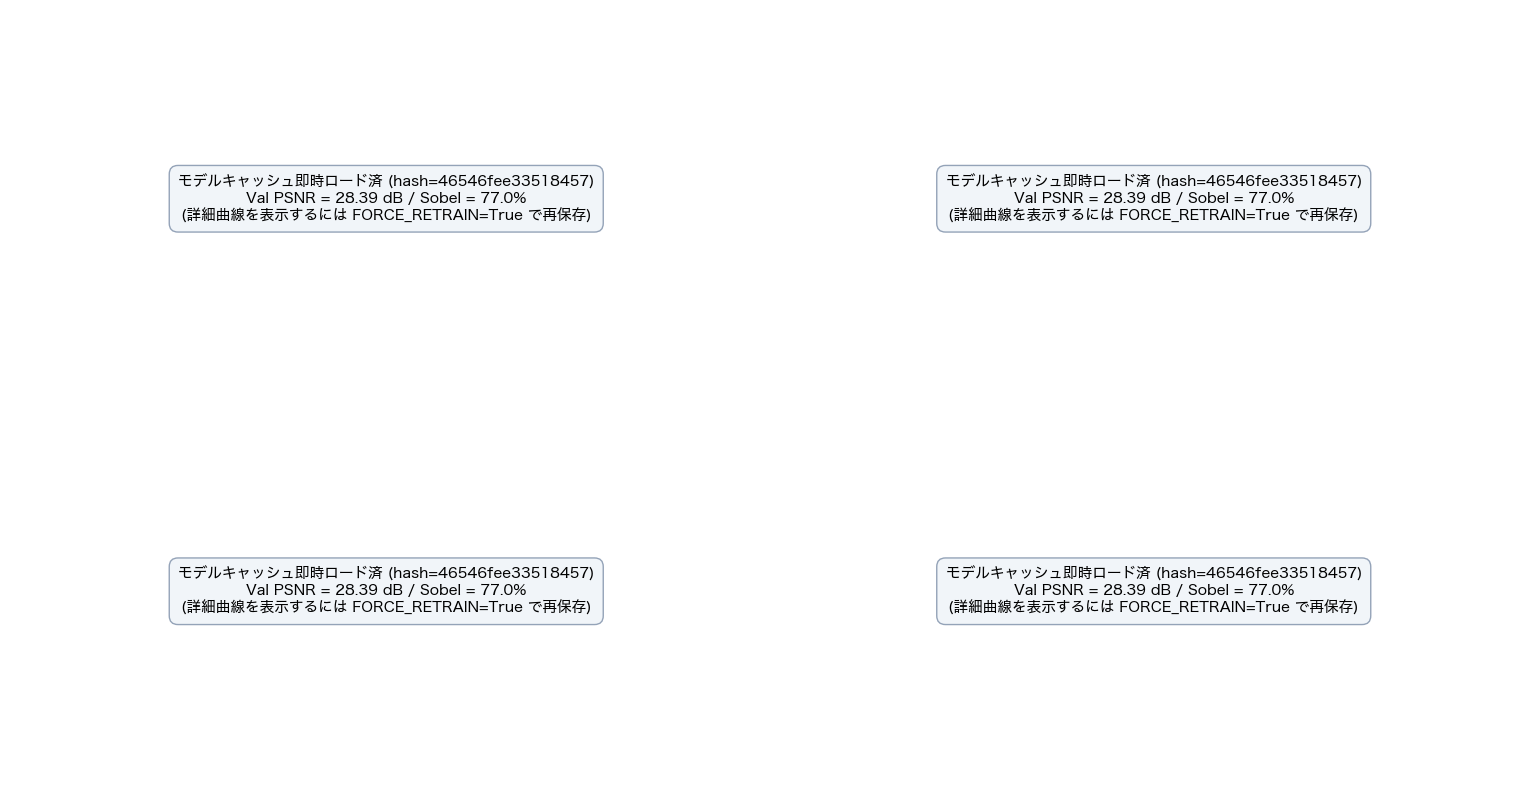

In [2]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import torch.nn as nn

class FastResSEBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.proj = (
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch))
            if in_ch != out_ch
            else nn.Identity()
        )
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        self.se = nn.Sequential(
            nn.Conv2d(out_ch, max(out_ch // 8, 8), 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(max(out_ch // 8, 8), out_ch, 1),
            nn.Sigmoid(),
        )
        self.act = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.net(x)
        w = self.se(h.mean(dim=(2, 3), keepdim=True))
        return self.act(self.proj(x) + h * w)

class PyramidContextBottleneck(nn.Module):
    def __init__(self, ch: int):
        super().__init__()
        q = ch // 4
        self.b1 = nn.Sequential(nn.Conv2d(ch, q, 1, bias=False), nn.BatchNorm2d(q), nn.ReLU(inplace=True))
        self.b2 = nn.Sequential(nn.Conv2d(ch, q, 3, padding=1, bias=False), nn.BatchNorm2d(q), nn.ReLU(inplace=True))
        self.b3 = nn.Sequential(nn.AvgPool2d(4), nn.Conv2d(ch, q, 1, bias=False), nn.BatchNorm2d(q), nn.ReLU(inplace=True))
        self.b4 = nn.Sequential(nn.Conv2d(ch, q, 1, bias=False), nn.ReLU(inplace=True))
        self.fuse = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch))
        self.act = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h, w = x.shape[-2:]
        p1 = self.b1(x)
        p2 = self.b2(x)
        p3 = F.interpolate(self.b3(x), size=(h, w), mode="nearest")
        p4 = self.b4(x.mean(dim=(2, 3), keepdim=True)).expand(-1, -1, h, w)
        return self.act(x + self.fuse(torch.cat([p1, p2, p3, p4], dim=1)))

class PriorGateFusion(nn.Module):
    def __init__(self, feat_ch: int, prior_ch: int = 2):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Conv2d(feat_ch + prior_ch, feat_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(feat_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(feat_ch, feat_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(feat_ch),
        )
        self.spatial_attn = nn.Sequential(nn.Conv2d(feat_ch + prior_ch, feat_ch, 1), nn.Sigmoid())
        self.act = nn.ReLU(inplace=True)

    def forward(self, feat: torch.Tensor, prior: torch.Tensor) -> torch.Tensor:
        cat = torch.cat([feat, prior], dim=1)
        return self.act(feat + self.gate(cat) * self.spatial_attn(cat))

class CoastlineGuidedSharpResSEUNet(nn.Module):
    def __init__(self, base: int = 48):
        super().__init__()
        self.e1 = FastResSEBlock(8, base)
        self.e2 = FastResSEBlock(base, base * 2)
        self.b = FastResSEBlock(base * 2, base * 4)
        self.pyr = PyramidContextBottleneck(base * 4)
        self.u2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.d2 = FastResSEBlock(base * 4, base * 2)
        self.u1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.d1 = FastResSEBlock(base * 2, base)
        self.prior_gate = PriorGateFusion(base, prior_ch=2)
        self.out = nn.Conv2d(base, 3, 1)
        self.pool = nn.MaxPool2d(2)

    def forward(self, corr: torch.Tensor, obs_mask: torch.Tensor, prior_2ch: torch.Tensor) -> torch.Tensor:
        e1 = self.e1(torch.cat([corr, obs_mask, prior_2ch], dim=1))
        e2 = self.e2(self.pool(e1))
        b = self.pyr(self.b(self.pool(e2)))
        d2 = self.d2(torch.cat([self.u2(b), e2], dim=1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], dim=1))
        pred = torch.sigmoid(self.out(self.prior_gate(d1, prior_2ch)))
        return corr * obs_mask + pred * (1.0 - obs_mask)

class MPSSpectralConv2d(nn.Module):
    '''Apple Silicon MPS ネイティブ対応 Spectral Normalization Conv2d (aten::vdot を不使用)'''
    def __init__(self, in_ch: int, out_ch: int, k: int = 4, stride: int = 2, padding: int = 1):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=padding)
        self.stride = stride
        self.padding = padding
        h = out_ch
        m = self.conv.weight.numel() // h
        self.register_buffer("u", F.normalize(torch.randn(h), dim=0))
        self.register_buffer("v", F.normalize(torch.randn(m), dim=0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        w_mat = self.conv.weight.reshape(self.conv.weight.size(0), -1)
        if self.training:
            with torch.no_grad():
                v_new = F.normalize(torch.matmul(w_mat.t(), self.u), dim=0, eps=1e-12)
                u_new = F.normalize(torch.matmul(w_mat, v_new), dim=0, eps=1e-12)
                self.v.copy_(v_new)
                self.u.copy_(u_new)
        u_cur = self.u.detach().clone()
        v_cur = self.v.detach().clone()
        sigma = (u_cur * torch.matmul(w_mat, v_cur)).sum().clamp_min(1e-12)
        return F.conv2d(x, self.conv.weight / sigma, self.conv.bias, stride=self.stride, padding=self.padding)

class SNCoastlinePatchDiscriminator(nn.Module):
    '''6ch 条件付き Markovian PatchGAN Discriminator ([Img_3ch, LandPrior, CoastEdge, HoleMask])'''
    def __init__(self, base: int = 48):
        super().__init__()
        self.l1 = nn.Sequential(MPSSpectralConv2d(6, base, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True))
        self.l2 = nn.Sequential(MPSSpectralConv2d(base, base * 2, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True))
        self.l3 = nn.Sequential(MPSSpectralConv2d(base * 2, base * 4, 4, 2, 1), nn.LeakyReLU(0.2, inplace=True))
        self.head = MPSSpectralConv2d(base * 4, 1, 3, 1, 1)

    def forward(self, img3: torch.Tensor, prior2: torch.Tensor, hm_any: torch.Tensor):
        x = torch.cat([img3, prior2, hm_any], dim=1)
        f1 = self.l1(x)
        f2 = self.l2(f1)
        f3 = self.l3(f2)
        logits = self.head(f3)
        return logits, [f1, f2, f3]

def gpu_sample_multiscale_6ch_batch(fine_gpu: torch.Tensor, wide_gpu: torch.Tensor, batch_size: int = 64, wide_prob: float = 0.15):
    n_wide = int(round(batch_size * wide_prob))
    n_fine = batch_size - n_wide
    idx_f = torch.randint(0, fine_gpu.size(0), (n_fine,), device=fine_gpu.device)
    if n_wide > 0:
        idx_w = torch.randint(0, wide_gpu.size(0), (n_wide,), device=wide_gpu.device)
        batch6 = torch.cat([fine_gpu[idx_f], wide_gpu[idx_w]], dim=0).clone()
        batch6 = batch6[torch.randperm(batch_size, device=batch6.device)]
    else:
        batch6 = fine_gpu[idx_f].clone()

    b, _, h, w = batch6.shape
    fh = torch.rand(b, 1, 1, 1, device=batch6.device) > 0.5
    fv = torch.rand(b, 1, 1, 1, device=batch6.device) > 0.5
    batch6 = torch.where(fh, batch6.flip(3), batch6)
    batch6 = torch.where(fv, batch6.flip(2), batch6)

    clean = batch6[:, :3]
    prior_2ch = batch6[:, 3:5]
    ch4_w = batch6[:, 5:6]  # (B, 1, H, W)
    c = 3

    gt_valid = (clean > 0.02).float()
    y_grid = torch.arange(h, device=clean.device).view(1, 1, h, 1)
    y0 = torch.randint(4, h - 25, (b, c, 1, 1), device=clean.device)
    sh0 = torch.randint(6, 24, (b, c, 1, 1), device=clean.device)
    m0 = ((y_grid < y0) | (y_grid >= y0 + sh0)).float()

    y1 = torch.randint(4, h - 20, (b, c, 1, 1), device=clean.device)
    sh1 = torch.randint(6, 18, (b, c, 1, 1), device=clean.device)
    m1 = ((y_grid < y1) | (y_grid >= y1 + sh1)).float()

    two_stripes = (torch.rand(b, c, 1, 1, device=clean.device) > 0.55).float()
    syn_mask = m0 * (1.0 - two_stripes * (1.0 - m1))

    keep_ch = torch.randint(0, c, (b, 1, 1, 1), device=clean.device)
    ch_idx = torch.arange(c, device=clean.device).view(1, c, 1, 1)
    keep_prob = torch.rand(b, 1, 1, 1, device=clean.device) > 0.30
    syn_mask = torch.where((ch_idx == keep_ch) & keep_prob, torch.ones_like(syn_mask), syn_mask)
    syn_mask = syn_mask.expand(b, c, h, w)

    obs_mask = gt_valid * syn_mask
    corrupted = clean * obs_mask
    hole_mask = gt_valid * (1.0 - syn_mask)
    return corrupted, obs_mask, hole_mask, clean, prior_2ch, ch4_w

class CoastlinePatchGANBaseLoss(nn.Module):
    '''策B 海岸線重み付き複合損失 ＋ 局所高周波テクスチャ分散保存損失 (Ch4信頼重み付き)'''
    def __init__(self, h: int = 64, w: int = 64, dev: torch.device = device):
        super().__init__()
        kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32, device=dev) / 8.0
        ky = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32, device=dev) / 8.0
        self.register_buffer("kx", kx.view(1, 1, 3, 3))
        self.register_buffer("ky", ky.view(1, 1, 3, 3))

        fy = torch.fft.fftfreq(h, device=dev)
        fx = torch.fft.rfftfreq(w, device=dev)
        yy, xx = torch.meshgrid(fy, fx, indexing="ij")
        r_norm = (torch.sqrt(xx ** 2 + yy ** 2) / 0.7071).clamp(0.0, 1.0)
        self.register_buffer("w_fft", (1.0 + 2.5 * r_norm).view(1, 1, h, w // 2 + 1))

    def _sobel(self, x_n1hw: torch.Tensor):
        return F.conv2d(x_n1hw, self.kx, padding=1), F.conv2d(x_n1hw, self.ky, padding=1)

    def _local_hf_std(self, x_bchw: torch.Tensor) -> torch.Tensor:
        # 5x5 平均を差し引いた高周波残差の局所 RMS エネルギー
        low = F.avg_pool2d(x_bchw, 5, stride=1, padding=2)
        hp = x_bchw - low
        return torch.sqrt(F.avg_pool2d(hp ** 2, 5, stride=1, padding=2) + 1e-6)

    def forward(self, pred: torch.Tensor, clean: torch.Tensor, hole_mask: torch.Tensor, obs_mask: torch.Tensor, prior_2ch: torch.Tensor, ch4_w: torch.Tensor | None = None) -> dict:
        b, c, h, w = pred.shape
        if ch4_w is None:
            w_ch = torch.ones((b, 3, 1, 1), device=pred.device)
        else:
            ch4_s = ch4_w.mean(dim=(2, 3), keepdim=True)
            ones = torch.ones_like(ch4_s)
            w_ch = torch.cat([ones, ones, ch4_s], dim=1)

        hm_w = hole_mask * w_ch
        coast_edge = prior_2ch[:, 1:2]
        w_coast = 1.0 + 3.0 * coast_edge

        charb = (torch.sqrt((pred - clean) ** 2 + 1e-6) * hm_w).sum() / (hm_w.sum() + 1e-6)

        v_band = ((hole_mask + obs_mask) > 0.5).float()
        dy_m = v_band[:, :, 1:, :] * v_band[:, :, :-1, :] * w_ch
        dx_m = v_band[:, :, :, 1:] * v_band[:, :, :, :-1] * w_ch
        edge1 = 0.5 * (
            (torch.abs((pred[:, :, 1:, :] - pred[:, :, :-1, :]) - (clean[:, :, 1:, :] - clean[:, :, :-1, :])) * dy_m).sum() / (dy_m.sum() + 1e-6)
            + (torch.abs((pred[:, :, :, 1:] - pred[:, :, :, :-1]) - (clean[:, :, :, 1:] - clean[:, :, :, :-1])) * dx_m).sum() / (dx_m.sum() + 1e-6)
        )

        # 大陸・海・雲色差 (Ch2-Ch1 は純実測のため重み1.0, Ch2-Ch4 は ch4_w で重み付け)
        valid_all = (v_band.min(dim=1)[0] > 0.5).float()
        hole_any = hole_mask.max(dim=1)[0]
        c_mask = ((hole_any > 0.5) & (valid_all > 0.5)).float()
        cw = c_mask * w_coast.squeeze(1)
        c21_p, c21_g = pred[:, 1:2] - pred[:, 0:1], clean[:, 1:2] - clean[:, 0:1]
        c24_p, c24_g = pred[:, 1:2] - pred[:, 2:3], clean[:, 1:2] - clean[:, 2:3]
        dc21 = torch.sqrt((c21_p.squeeze(1) - c21_g.squeeze(1)) ** 2 + 1e-6)
        dc24 = torch.sqrt((c24_p.squeeze(1) - c24_g.squeeze(1)) ** 2 + 1e-6)
        w4_2d = w_ch[:, 2, :, :]
        contrast = ((dc21 + w4_2d * dc24) / (1.0 + w4_2d) * cw).sum() / (cw.sum() + 1e-6)

        v3_c = (F.avg_pool2d(valid_all.unsqueeze(1), 3, stride=1, padding=1) > 0.99).float()
        t3_c = (F.max_pool2d(hole_any.unsqueeze(1), 3, stride=1, padding=1) > 0.5).float() * v3_c * w_coast
        c21_px, c21_py = self._sobel(c21_p)
        c21_gx, c21_gy = self._sobel(c21_g)
        sobel_c21 = (
            0.5 * (torch.abs(c21_px - c21_gx) + torch.abs(c21_py - c21_gy))
            + 0.9 * torch.abs(torch.sqrt(c21_px ** 2 + c21_py ** 2 + 1e-6) - torch.sqrt(c21_gx ** 2 + c21_gy ** 2 + 1e-6))
        )
        sobel_loss = (sobel_c21 * t3_c).sum() / (t3_c.sum() + 1e-6)

        v3_b = (F.avg_pool2d(v_band, 3, stride=1, padding=1) > 0.99).float()
        t3_b = (F.max_pool2d(hole_mask, 3, stride=1, padding=1) > 0.5).float() * v3_b * w_ch
        px_b, py_b = self._sobel(pred.reshape(-1, 1, h, w))
        gx_b, gy_b = self._sobel(clean.reshape(-1, 1, h, w))
        mag_bp = torch.sqrt(px_b ** 2 + py_b ** 2 + 1e-6).view(b, c, h, w)
        mag_bg = torch.sqrt(gx_b ** 2 + gy_b ** 2 + 1e-6).view(b, c, h, w)
        sobel_mag_b = (torch.abs(mag_bp - mag_bg) * t3_b).sum() / (t3_b.sum() + 1e-6)
        sobel_total = 0.70 * sobel_loss + 0.50 * sobel_mag_b

        v_sum = v_band.sum(dim=(2, 3), keepdim=True).clamp_min(1.0)
        ch_mean = (clean * v_band).sum(dim=(2, 3), keepdim=True) / v_sum
        clean_filled = torch.where(v_band > 0.5, clean, ch_mean)
        comp_fft = torch.where(hole_mask > 0.5, pred, clean_filled)
        fp = torch.log1p(torch.fft.rfft2(comp_fft, norm="ortho").abs())
        fg = torch.log1p(torch.fft.rfft2(clean_filled, norm="ortho").abs())
        scale = (1.0 / hole_mask.mean().clamp_min(0.15)).clamp_max(2.0)
        fft_loss = ((torch.abs(fp - fg) * self.w_fft).mean()) * scale

        # 局所高周波テクスチャエネルギー保存 (L1平均ボケを抑止し雲・地形の粒状分散を一致)
        v5_b = (F.avg_pool2d(v_band[:, :2], 5, stride=1, padding=2) > 0.98).float()
        h5_b = (F.max_pool2d(hole_mask[:, :2], 5, stride=1, padding=2) > 0.5).float() * v5_b
        tex_p = self._local_hf_std(pred[:, :2])
        tex_g = self._local_hf_std(clean[:, :2])
        tex_loss = (torch.abs(tex_p - tex_g) * h5_b).sum() / (h5_b.sum() + 1e-6)

        total = charb + 0.35 * edge1 + 0.34 * contrast + 0.22 * sobel_total + 0.04 * fft_loss + 0.12 * tex_loss
        return {
            "total": total, "charb": charb.detach(), "sobel": sobel_total.detach(),
            "fft": fft_loss.detach(), "tex": tex_loss.detach(),
        }

def predict_4way_tta_8ch(net: nn.Module, corr: torch.Tensor, omask: torch.Tensor, prior2: torch.Tensor) -> torch.Tensor:
    n = corr.size(0)
    c_cat = torch.cat([corr, corr.flip(3), corr.flip(2), corr.flip((2, 3))], dim=0)
    m_cat = torch.cat([omask, omask.flip(3), omask.flip(2), omask.flip((2, 3))], dim=0)
    p_cat = torch.cat([prior2, prior2.flip(3), prior2.flip(2), prior2.flip((2, 3))], dim=0)
    o0, o1, o2, o3 = net(c_cat, m_cat, p_cat).split(n, dim=0)
    merged = 0.25 * (o0 + o1.flip(3) + o2.flip(2) + o3.flip((2, 3)))
    return corr * omask + merged * (1.0 - omask)

def build_fixed_val_tensors_5ch(val_5ch_np: np.ndarray, fixed_seed: int = 2026):
    corr_l, om_l, hm_l, cln_l, pr_l = [], [], [], [], []
    for idx, patch5 in enumerate(val_5ch_np):
        clean, prior2 = torch.from_numpy(patch5[:3]), torch.from_numpy(patch5[3:5])
        c, h, w = clean.shape
        gt_valid = (clean > 0.02).float()
        rng = np.random.default_rng(fixed_seed + idx)
        syn_mask = torch.ones((c, h, w), dtype=torch.float32)
        drop_bands = rng.choice(c, size=int(rng.integers(1, c + 1)), replace=False)
        for b in drop_bands:
            for _ in range(int(rng.integers(1, 3))):
                sh = int(rng.integers(6, 15))
                y0 = int(rng.integers(4, h - sh - 4))
                syn_mask[int(b), y0:y0 + sh, :] = 0.0
        om = gt_valid * syn_mask
        corr_l.append(clean * om)
        om_l.append(om)
        hm_l.append(gt_valid * (1.0 - syn_mask))
        cln_l.append(clean)
        pr_l.append(prior2)
    return tuple(torch.stack(x).to(device) for x in (corr_l, om_l, hm_l, cln_l, pr_l))

val_corr_g, val_om_g, val_hm_g, val_cln_g, val_pr_g = build_fixed_val_tensors_5ch(meteor_val_5ch, fixed_seed=2026)
criterion = CoastlinePatchGANBaseLoss(64, 64, dev=device).to(device)

def compute_val_metrics(pred: torch.Tensor) -> dict:
    diff = pred - val_cln_g
    px = max(val_hm_g.sum().item(), 1e-6)
    l1 = (torch.abs(diff) * val_hm_g).sum().item() / px
    mse = ((diff ** 2) * val_hm_g).sum().item() / px
    psnr = -10.0 * np.log10(max(mse, 1e-12))

    hm_any = val_hm_g.max(dim=1)[0]
    dc_err = (torch.abs((pred[:, 1] - pred[:, 0]) - (val_cln_g[:, 1] - val_cln_g[:, 0])) * hm_any).sum().item() / max(hm_any.sum().item(), 1e-6)

    c21_p, c21_g = pred[:, 1:2] - pred[:, 0:1], val_cln_g[:, 1:2] - val_cln_g[:, 0:1]
    gx_p, gy_p = criterion._sobel(c21_p)
    gx_g, gy_g = criterion._sobel(c21_g)
    mag_p = torch.sqrt(gx_p ** 2 + gy_p ** 2 + 1e-8).squeeze(1)
    mag_g = torch.sqrt(gx_g ** 2 + gy_g ** 2 + 1e-8).squeeze(1)
    touch = (F.max_pool2d(hm_any.unsqueeze(1), 3, stride=1, padding=1).squeeze(1) > 0.5).float()
    sharp_ratio = ((mag_p * touch).sum().item() / max((mag_g * touch).sum().item(), 1e-6)) * 100.0

    fp = torch.fft.rfft2(pred, norm="ortho").abs()
    fg = torch.fft.rfft2(val_cln_g, norm="ortho").abs()
    hf_mask = ((criterion.w_fft - 1.0) / 2.5 >= 0.25).float()
    fft_hf_ratio = (((fp * hf_mask).sum().item()) / max((fg * hf_mask).sum().item(), 1e-6)) * 100.0

    # 局所高周波テクスチャ分散保持率 (5x5 high-pass RMS in Ch1/Ch2 hole)
    hp_p = criterion._local_hf_std(pred[:, :2])
    hp_g = criterion._local_hf_std(val_cln_g[:, :2])
    hm_12 = val_hm_g[:, :2]
    tex_ratio = ((hp_p * hm_12).sum().item() / max((hp_g * hm_12).sum().item(), 1e-6)) * 100.0
    return {
        "l1": l1, "psnr": psnr, "dc_err": dc_err,
        "sharp_pct": sharp_ratio, "fft_hf_pct": fft_hf_ratio, "tex_pct": tex_ratio,
    }

from model_cache import check_model_cache, save_model_cache  # noqa: E402

MODEL_DIR = REPO_ROOT / "projects" / "radio-ml" / "models"
BUNDLE_PATH = MODEL_DIR / "nb09_coastline_patchgan_bundle.pt"
FORCE_RETRAIN = False  # 条件を変更せずに強制再学習したい場合のみ True

NB09_TRAIN_CONFIG = {
    "arch": "CoastlineGuidedSharpResSEUNet+SNCoastlinePatchDiscriminator",
    "in_ch": 8,
    "base": 48,
    "seed": 42,
    "batch_size": 64,
    "steps_s1": 180,
    "steps_s2a": 120,
    "steps_s2b": 192,
    "lr_s1": 2e-3,
    "lr_g": 8e-4,
    "lr_d": 2e-4,
    "loss_weights": {
        "edge1": 0.35,
        "contrast": 0.34,
        "sobel": 0.22,
        "fft": 0.04,
        "tex": 0.12,
        "fm": 0.12,
        "adv": 0.018,
    },
    "dataset_counts": {
        "hima_64": int(len(hima_64_gpu)),
        "hima_2x": int(len(hima_2x_gpu)),
        "ft_64": int(len(ft_64_gpu)),
        "ft_2x": int(len(ft_2x_gpu)),
    },
}

torch.manual_seed(42)
net_g = CoastlineGuidedSharpResSEUNet(base=48).to(device)
net_d = SNCoastlinePatchDiscriminator(base=48).to(device)
n_params_g = sum(p.numel() for p in net_g.parameters())
n_params_d = sum(p.numel() for p in net_d.parameters())

psnr_hist, sharp_hist, tex_hist = [], [], []
loss_log = {"charb": [], "sobel": [], "tex": [], "d_loss": [], "fm": []}

cache_hit, cfg_hash, cached_bundle = check_model_cache(BUNDLE_PATH, NB09_TRAIN_CONFIG, force_retrain=FORCE_RETRAIN)

if cache_hit:
    t_load0 = time.perf_counter()
    net_g.load_state_dict(cached_bundle["state_dict"])
    if "net_d_state_dict" in cached_bundle:
        net_d.load_state_dict(cached_bundle["net_d_state_dict"])
    psnr_hist = list(cached_bundle.get("psnr_hist", []))
    sharp_hist = list(cached_bundle.get("sharp_hist", []))
    tex_hist = list(cached_bundle.get("tex_hist", []))
    loss_log = cached_bundle.get("loss_log", {"charb": [], "sobel": [], "tex": [], "d_loss": [], "fm": []})
    train_dt = float(cached_bundle.get("train_dt", 0.0))
    net_g.eval()
    print(f"策C PatchGAN キャッシュロード完了 ({time.perf_counter() - t_load0:.2f}s | 元学習={train_dt:.1f}s | Val PSNR={cached_bundle.get('val_psnr', 0.0):.2f} dB)", flush=True)
else:
    t_train_start = time.perf_counter()
    total_epochs = 41

    # --- Stage 1: ひまわり8号 5シーン事前学習 (15 epochs x 12 steps = 180 steps) ---
    opt_s1 = torch.optim.AdamW(net_g.parameters(), lr=2e-3, weight_decay=1e-4)
    sched_s1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_s1, T_max=180)
    for epoch in range(15):
        net_g.train()
        for _ in range(12):
            corr, om, hm, cln, pr2, w4 = gpu_sample_multiscale_6ch_batch(hima_64_gpu, hima_2x_gpu, batch_size=64, wide_prob=0.15)
            opt_s1.zero_grad(set_to_none=True)
            ld = criterion(net_g(corr, om, pr2), cln, hm, om, pr2, w4)
            ld["total"].backward()
            opt_s1.step()
            sched_s1.step()
            for k in ["charb", "sobel", "tex"]:
                loss_log[k].append(float(ld[k].item()))
            loss_log["d_loss"].append(0.0)
            loss_log["fm"].append(0.0)
        net_g.eval()
        with torch.no_grad():
            m = compute_val_metrics(predict_4way_tta_8ch(net_g, val_corr_g, val_om_g, val_pr_g))
        psnr_hist.append(m["psnr"])
        sharp_hist.append(m["sharp_pct"])
        tex_hist.append(m["tex_pct"])
        ep_done = epoch + 1
        if ep_done % 5 == 0 or ep_done == 15:
            el = time.perf_counter() - t_train_start
            eta = (el / ep_done) * (total_epochs - ep_done)
            print(f"  [Stage 1 ひまわり | Epoch {ep_done:2d}/{total_epochs} ({ep_done/total_epochs*100:4.1f}%) | Elapsed {el:5.1f}s | ETA {eta:5.1f}s] Val={m['psnr']:.2f}dB", flush=True)

    # --- Stage 2a: 5倍拡張 METEOR 実測 Warmup FT (10 epochs x 12 steps = 120 steps) ---
    opt_g = torch.optim.AdamW(net_g.parameters(), lr=8e-4, weight_decay=1e-4)
    opt_d = torch.optim.AdamW(net_d.parameters(), lr=2e-4, betas=(0.5, 0.999), weight_decay=1e-4)
    sched_g = torch.optim.lr_scheduler.CosineAnnealingLR(opt_g, T_max=312)
    sched_d = torch.optim.lr_scheduler.CosineAnnealingLR(opt_d, T_max=192)

    for epoch in range(10):
        net_g.train()
        wp = 0.15 if epoch < 5 else 0.0
        for _ in range(12):
            corr, om, hm, cln, pr2, w4 = gpu_sample_multiscale_6ch_batch(ft_64_gpu, ft_2x_gpu, batch_size=64, wide_prob=wp)
            opt_g.zero_grad(set_to_none=True)
            ld = criterion(net_g(corr, om, pr2), cln, hm, om, pr2, w4)
            ld["total"].backward()
            opt_g.step()
            sched_g.step()
            for k in ["charb", "sobel", "tex"]:
                loss_log[k].append(float(ld[k].item()))
            loss_log["d_loss"].append(0.0)
            loss_log["fm"].append(0.0)
        net_g.eval()
        with torch.no_grad():
            m = compute_val_metrics(predict_4way_tta_8ch(net_g, val_corr_g, val_om_g, val_pr_g))
        psnr_hist.append(m["psnr"])
        sharp_hist.append(m["sharp_pct"])
        tex_hist.append(m["tex_pct"])
        ep_done = 15 + epoch + 1
        if (epoch + 1) % 5 == 0 or epoch == 9:
            el = time.perf_counter() - t_train_start
            eta = (el / ep_done) * (total_epochs - ep_done)
            print(f"  [Stage 2a METEOR | Epoch {ep_done:2d}/{total_epochs} ({ep_done/total_epochs*100:4.1f}%) | Elapsed {el:5.1f}s | ETA {eta:5.1f}s] Val={m['psnr']:.2f}dB", flush=True)

    # --- Stage 2b: PatchGAN + 3層 Feature Matching 共同学習 (16 epochs x 12 steps = 192 steps) ---
    for epoch in range(16):
        net_g.train()
        net_d.train()
        for _ in range(12):
            corr, om, hm, cln, pr2, w4 = gpu_sample_multiscale_6ch_batch(ft_64_gpu, ft_2x_gpu, batch_size=64, wide_prob=0.0)
            hm_any = hm.max(dim=1, keepdim=True)[0]
            valid_gt_mask = (cln > 0.02).all(dim=1, keepdim=True).float()
            pred_raw = net_g(corr, om, pr2)

            net_d.train()
            real_in = cln * valid_gt_mask + pred_raw.detach() * (1.0 - valid_gt_mask)
            fake_in = pred_raw.detach()
            opt_d.zero_grad(set_to_none=True)
            d_real, _ = net_d(real_in, pr2, hm_any)
            d_fake, _ = net_d(fake_in, pr2, hm_any)
            d_loss = 0.5 * (F.relu(0.95 - d_real).mean() + F.relu(0.95 + d_fake).mean())
            d_loss.backward()
            opt_d.step()
            sched_d.step()

            net_d.eval()
            opt_g.zero_grad(set_to_none=True)
            ld = criterion(pred_raw, cln, hm, om, pr2, w4)
            fake_g_in = pred_raw * valid_gt_mask + real_in.detach() * (1.0 - valid_gt_mask)
            with torch.no_grad():
                _, f_real = net_d(real_in, pr2, hm_any)
            d_fake_g, f_fake = net_d(fake_g_in, pr2, hm_any)
            fm_loss = sum(F.l1_loss(ff, fr.detach()) for ff, fr in zip(f_fake, f_real)) / 3.0
            adv_loss = -d_fake_g.mean()
            g_total = ld["total"] + 0.12 * fm_loss + 0.018 * adv_loss
            g_total.backward()
            opt_g.step()
            sched_g.step()

            for k in ["charb", "sobel", "tex"]:
                loss_log[k].append(float(ld[k].item()))
            loss_log["d_loss"].append(float(d_loss.item()))
            loss_log["fm"].append(float(fm_loss.item()))

        net_g.eval()
        with torch.no_grad():
            m = compute_val_metrics(predict_4way_tta_8ch(net_g, val_corr_g, val_om_g, val_pr_g))
        psnr_hist.append(m["psnr"])
        sharp_hist.append(m["sharp_pct"])
        tex_hist.append(m["tex_pct"])
        ep_done = 25 + epoch + 1
        if (epoch + 1) % 4 == 0 or epoch == 15:
            el = time.perf_counter() - t_train_start
            eta = (el / ep_done) * (total_epochs - ep_done)
            print(f"  [Stage 2b PatchGAN | Epoch {ep_done:2d}/{total_epochs} ({ep_done/total_epochs*100:4.1f}%) | Elapsed {el:5.1f}s | ETA {eta:5.1f}s] Val={m['psnr']:.2f}dB / Sobel={m['sharp_pct']:.1f}%", flush=True)

    if device.type == "mps":
        torch.mps.synchronize()
    train_dt = time.perf_counter() - t_train_start
    if device.type == "mps":
        print(f"策C PatchGAN 共同学習完了 (G={n_params_g/1e6:.2f}M, D={n_params_d/1e6:.2f}M | 492 steps, {train_dt:.1f}s) | MPS ピーク: {torch.mps.driver_allocated_memory()/1e6:.1f} MB")
    else:
        print(f"策C PatchGAN 共同学習完了 (492 steps, {train_dt:.1f}s)")

    net_g.eval()
    with torch.no_grad():
        m_final = compute_val_metrics(predict_4way_tta_8ch(net_g, val_corr_g, val_om_g, val_pr_g))
    save_model_cache(BUNDLE_PATH, NB09_TRAIN_CONFIG, {
        "state_dict": {k: v.cpu() for k, v in net_g.state_dict().items()},
        "net_d_state_dict": {k: v.cpu() for k, v in net_d.state_dict().items()},
        "psnr_hist": psnr_hist,
        "sharp_hist": sharp_hist,
        "tex_hist": tex_hist,
        "loss_log": loss_log,
        "train_dt": train_dt,
        "clean_land_hw": clean_land_hw,
        "W_av221": W_av221,
        "W_msu124": W_msu124,
        "W_ch4_proxy": W_ch4_proxy,
        "val_psnr": float(m_final["psnr"]),
    })

# --- 図2: 4パネル学習曲線 (PSNR / 海岸線エッジ&テクスチャ保持率 / G損失 / D&FM損失) ---
fig, axes = plt.subplots(2, 2, figsize=(15.5, 8.0))
if len(psnr_hist) > 0 and len(loss_log.get("charb", [])) > 0:
    eps = np.arange(1, len(psnr_hist) + 1)

    axes[0, 0].plot(eps, psnr_hist, color="#1D3557", lw=2.2, label="09 策C+自動Prior+5倍データ")
    axes[0, 0].axvline(15.5, linestyle=":", color="#6B6963", label="Stage 1→2a (METEOR FT)")
    axes[0, 0].axvline(25.5, linestyle="--", color="#E63946", label="Stage 2a→2b (PatchGAN開始)")
    axes[0, 0].axhline(28.13, linestyle="--", color="#2A9D8F", label="08 策B (28.13 dB)")
    axes[0, 0].set_title("Val Hole PSNR 推移 (全41 epochs / 492 steps)")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Hole PSNR [dB]")
    axes[0, 0].legend(fontsize=8.2)
    axes[0, 0].grid(alpha=0.25)

    axes[0, 1].plot(eps, sharp_hist, color="#2A9D8F", lw=2.1, label="海岸線 Sobel 保存率 [%]")
    axes[0, 1].plot(eps, tex_hist, color="#E76F51", lw=2.1, label="高周波テクスチャ分散保持率 [%]")
    axes[0, 1].axhline(100.0, linestyle="--", color="#457B9D", label="理想値 100%")
    axes[0, 1].axvline(15.5, linestyle=":", color="#6B6963")
    axes[0, 1].axvline(25.5, linestyle="--", color="#E63946")
    axes[0, 1].set_title("鮮鋭度 (Sobel) ＆ ミクロ質感 (5x5高周波分散) 保持率")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("保持率 [%]")
    axes[0, 1].legend(fontsize=8.2)
    axes[0, 1].grid(alpha=0.25)

    steps = np.arange(1, len(loss_log["charb"]) + 1)
    axes[1, 0].plot(steps, loss_log["charb"], lw=1.5, label="Charbonnier L1")
    axes[1, 0].plot(steps, loss_log["sobel"], lw=1.5, label="海岸線重み Sobel 損失")
    axes[1, 0].plot(steps, loss_log["tex"], lw=1.5, label="局所高周波分散損失")
    axes[1, 0].axvline(180, linestyle=":", color="#6B6963")
    axes[1, 0].axvline(300, linestyle="--", color="#E63946")
    axes[1, 0].set_title("Generator 再構成・鮮鋭・質感損失の推移")
    axes[1, 0].set_xlabel("Step")
    axes[1, 0].set_ylabel("Loss")
    axes[1, 0].legend(fontsize=8.2)
    axes[1, 0].grid(alpha=0.25)

    axes[1, 1].plot(steps[300:], loss_log["d_loss"][300:], color="#6A4C93", lw=1.6, label="PatchGAN Hinge D_loss")
    axes[1, 1].plot(steps[300:], loss_log["fm"][300:], color="#F4A261", lw=1.6, label="3層 Feature Matching 損失")
    axes[1, 1].set_title("Stage 2b: PatchGAN 識別器 & Feature Matching 損失")
    axes[1, 1].set_xlabel("Step (Stage 2b: 301〜492)")
    axes[1, 1].set_ylabel("Loss")
    axes[1, 1].legend(fontsize=8.2)
    axes[1, 1].grid(alpha=0.25)
else:
    with torch.no_grad():
        _m_cached = compute_val_metrics(predict_4way_tta_8ch(net_g, val_corr_g, val_om_g, val_pr_g))
    for _ax in axes.ravel():
        _ax.axis("off")
        _ax.text(
            0.5, 0.5,
            f"モデルキャッシュ即時ロード済 (hash={cfg_hash})\nVal PSNR = {_m_cached['psnr']:.2f} dB / Sobel = {_m_cached['sharp_pct']:.1f}%\n(詳細曲線を表示するには FORCE_RETRAIN=True で再保存)",
            ha="center", va="center", fontsize=10.5,
            bbox={"boxstyle": "round,pad=0.6", "facecolor": "#F1F5F9", "edgecolor": "#94A3B8"},
        )

plt.tight_layout()
plt.show()

## 3. 標準ベンチマーク検証（`fixed_seed=2026`, 48 Val Patches）— 歴代モデル比較と高周波質感評価

`04 / 05 / 06 / 07 / 08` と同一の 48 枚の未知検証パッチ（`fixed_seed=2026`）上で、従来の L1 / PSNR / `Ch2-Ch1` 色差 / Sobel 保存率 / 2D-FFT 高周波保存率に加え、新たに **局所高周波テクスチャ分散保持率（5×5 high-pass RMS Ratio）** を定量評価します。さらに海岸線代表 4 パッチについて高周波成分マップを含めて視覚比較します。

=== 標準 Val ベンチマーク 48 枚 (fixed_seed=2026) ===
  04 マルチバンド MiniUNet             -> Hole L1: 0.0270 | PSNR: 28.17 dB
  05 HeavyResSEUNet (4-way TTA)        -> Hole L1: 0.0279 | PSNR: 28.03 dB
  06 ContinentResSEUNet (4-way TTA)    -> Hole L1: 0.0246 | PSNR: 28.72 dB | Ch2-Ch1 L1: 0.0170
  07 策A MultiScale+Sobel+FFT (4-way)  -> Hole L1: 0.0266 | PSNR: 28.27 dB | Ch2-Ch1 L1: 0.0174 | Sobel保存: 76.8% | FFT高周波: 97.4%
  08 策B CoastlineGuided (4-way TTA)   -> Hole L1: 0.0266 | PSNR: 28.13 dB | Ch2-Ch1 L1: 0.0161 | Sobel保存: 80.1% | FFT高周波: 97.9%
  09 策C+自動Prior+5倍データ (単一推論)-> Hole L1: 0.0258 | PSNR: 28.35 dB | Ch2-Ch1 L1: 0.0165 | Sobel保存: 78.1% | FFT高周波: 97.8% | 質感分散比: 78.2%
  09 策C+自動Prior+5倍データ (4-wayTTA)-> Hole L1: 0.0257 | PSNR: 28.39 dB | Ch2-Ch1 L1: 0.0163 | Sobel保存: 77.0% | FFT高周波: 97.5% | 質感分散比: 77.2%


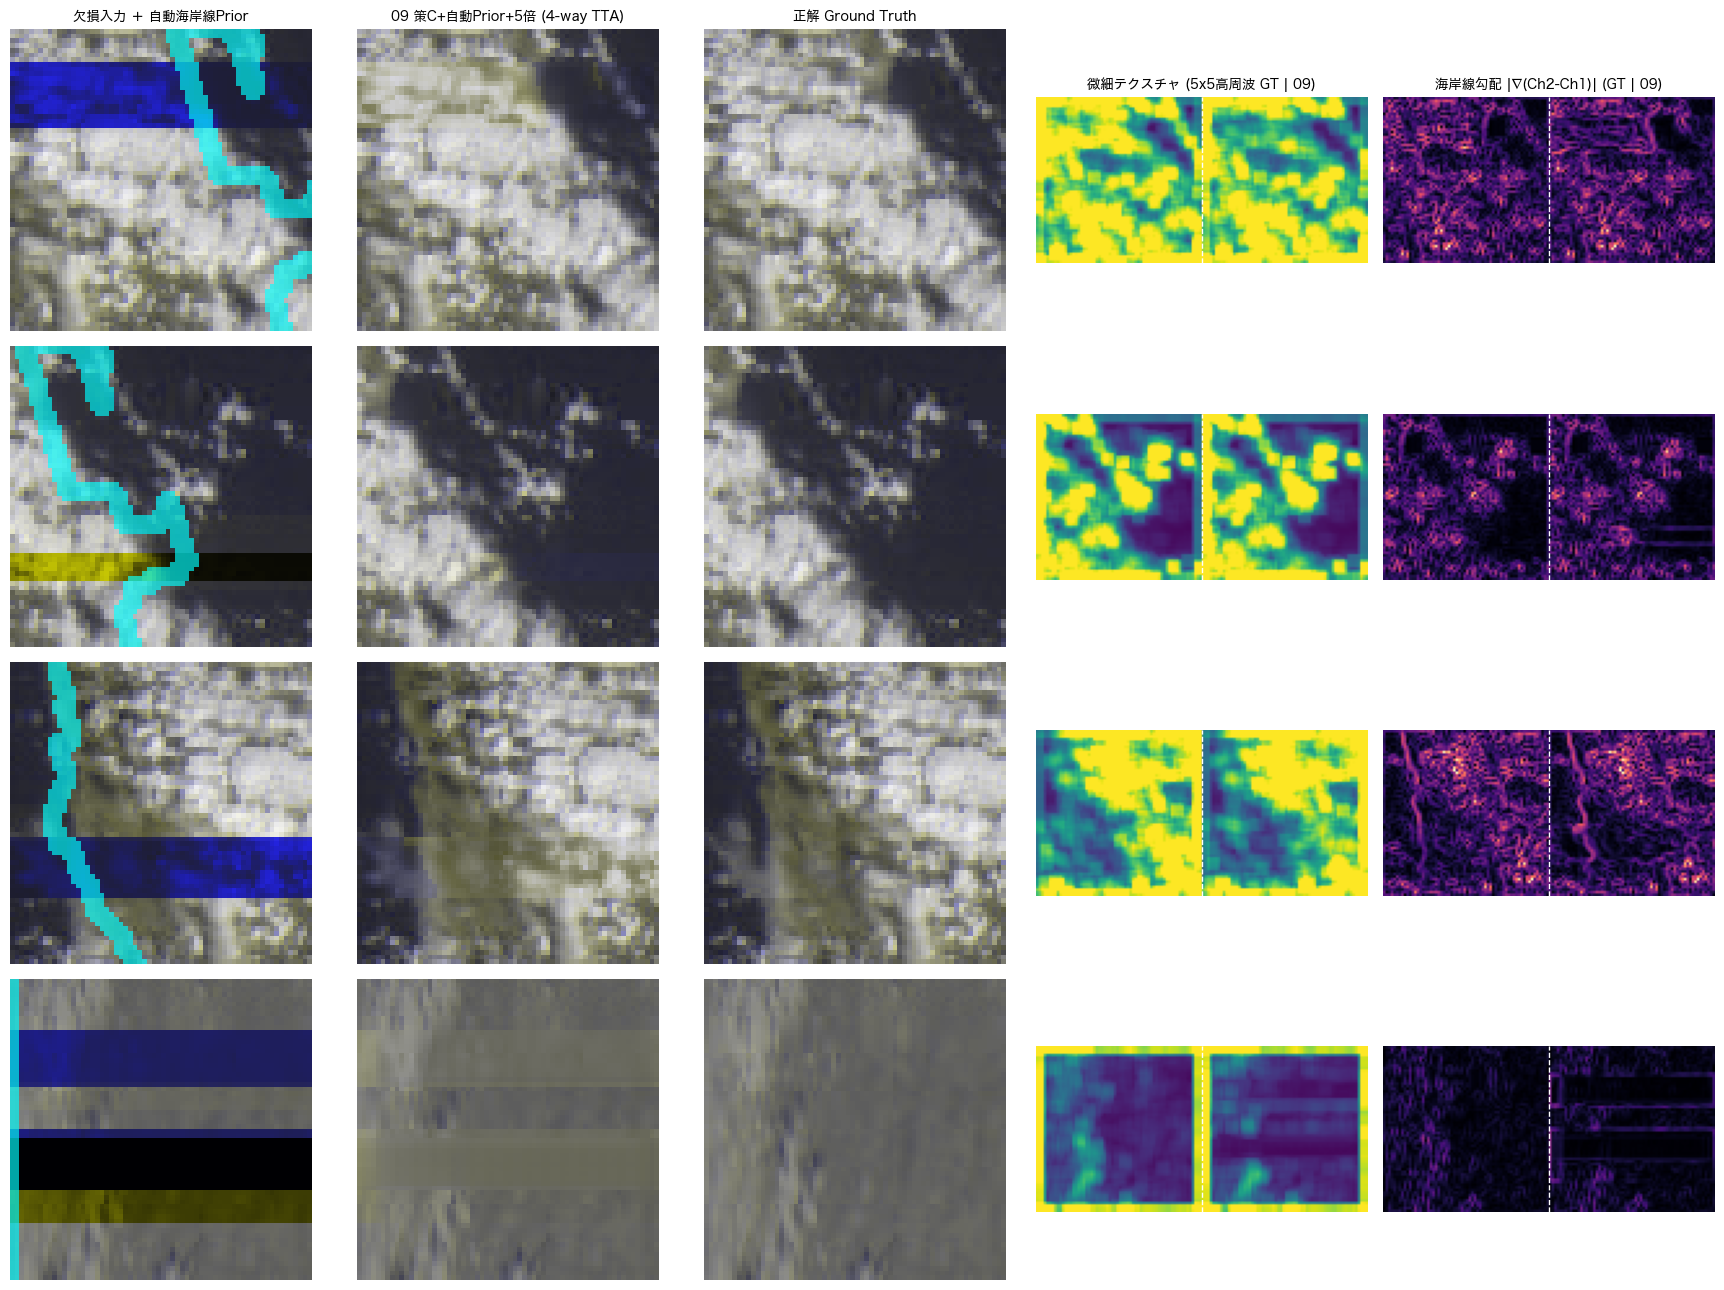

In [3]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

net_g.eval()
with torch.no_grad():
    pred_single = net_g(val_corr_g, val_om_g, val_pr_g)
    pred_tta = predict_4way_tta_8ch(net_g, val_corr_g, val_om_g, val_pr_g)

m_single = compute_val_metrics(pred_single)
m_tta = compute_val_metrics(pred_tta)

print("=== 標準 Val ベンチマーク 48 枚 (fixed_seed=2026) ===")
print("  04 マルチバンド MiniUNet             -> Hole L1: 0.0270 | PSNR: 28.17 dB")
print("  05 HeavyResSEUNet (4-way TTA)        -> Hole L1: 0.0279 | PSNR: 28.03 dB")
print("  06 ContinentResSEUNet (4-way TTA)    -> Hole L1: 0.0246 | PSNR: 28.72 dB | Ch2-Ch1 L1: 0.0170")
print("  07 策A MultiScale+Sobel+FFT (4-way)  -> Hole L1: 0.0266 | PSNR: 28.27 dB | Ch2-Ch1 L1: 0.0174 | Sobel保存: 76.8% | FFT高周波: 97.4%")
print("  08 策B CoastlineGuided (4-way TTA)   -> Hole L1: 0.0266 | PSNR: 28.13 dB | Ch2-Ch1 L1: 0.0161 | Sobel保存: 80.1% | FFT高周波: 97.9%")
print(f"  09 策C+自動Prior+5倍データ (単一推論)-> Hole L1: {m_single['l1']:.4f} | PSNR: {m_single['psnr']:.2f} dB | Ch2-Ch1 L1: {m_single['dc_err']:.4f} | Sobel保存: {m_single['sharp_pct']:.1f}% | FFT高周波: {m_single['fft_hf_pct']:.1f}% | 質感分散比: {m_single['tex_pct']:.1f}%")
print(f"  09 策C+自動Prior+5倍データ (4-wayTTA)-> Hole L1: {m_tta['l1']:.4f} | PSNR: {m_tta['psnr']:.2f} dB | Ch2-Ch1 L1: {m_tta['dc_err']:.4f} | Sobel保存: {m_tta['sharp_pct']:.1f}% | FFT高周波: {m_tta['fft_hf_pct']:.1f}% | 質感分散比: {m_tta['tex_pct']:.1f}%")

# --- 図3: 海岸線代表 Val パッチ 4 枚の 5 列拡大検証 (入力 / 09復元 / GT / 質感高周波 / 海岸線Sobel) ---
coast_hole_score = ((val_hm_g.max(dim=1)[0] > 0.5).float() * val_pr_g[:, 1]).sum(dim=(1, 2))
top4 = torch.topk(coast_hole_score, 4).indices.cpu().tolist()

kx_np = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32) / 8.0
ky_np = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32) / 8.0
sobel_kx_c = torch.from_numpy(kx_np).view(1, 1, 3, 3)
sobel_ky_c = torch.from_numpy(ky_np).view(1, 1, 3, 3)

fig, axes = plt.subplots(4, 5, figsize=(17.5, 13.0))
col_titles = [
    "欠損入力 ＋ 自動海岸線Prior",
    "09 策C+自動Prior+5倍 (4-way TTA)",
    "正解 Ground Truth",
    "微細テクスチャ (5x5高周波 GT | 09)",
    "海岸線勾配 |∇(Ch2-Ch1)| (GT | 09)",
]

with torch.no_grad():
    hp_gt_all = criterion._local_hf_std(val_cln_g[:, 1:2]).squeeze(1).cpu().numpy()
    hp_pr_all = criterion._local_hf_std(pred_tta[:, 1:2]).squeeze(1).cpu().numpy()

for r_idx, p_idx in enumerate(top4):
    inp_vis = render_satdump_av221(val_corr_g[p_idx].cpu().numpy().transpose(1, 2, 0), (val_om_g[p_idx].max(dim=0)[0] > 0.5).unsqueeze(-1).cpu().numpy())
    edge_p = val_pr_g[p_idx, 1].cpu().numpy() > 0.72
    inp_ov = inp_vis.copy()
    inp_ov[edge_p] = 0.35 * inp_ov[edge_p] + 0.65 * np.array([0.0, 1.0, 1.0], dtype=np.float32)
    fin_vis = render_satdump_av221(pred_tta[p_idx].cpu().numpy().transpose(1, 2, 0))
    gt_vis = render_satdump_av221(val_cln_g[p_idx].cpu().numpy().transpose(1, 2, 0))

    tex_pair = np.concatenate([hp_gt_all[p_idx], hp_pr_all[p_idx]], axis=1)

    c21_g = (val_cln_g[p_idx:p_idx + 1, 1:2] - val_cln_g[p_idx:p_idx + 1, 0:1]).cpu()
    c21_p = (pred_tta[p_idx:p_idx + 1, 1:2] - pred_tta[p_idx:p_idx + 1, 0:1]).cpu()
    mag_g = torch.sqrt(F.conv2d(c21_g, sobel_kx_c, padding=1) ** 2 + F.conv2d(c21_g, sobel_ky_c, padding=1) ** 2 + 1e-8).squeeze().numpy()
    mag_p = torch.sqrt(F.conv2d(c21_p, sobel_kx_c, padding=1) ** 2 + F.conv2d(c21_p, sobel_ky_c, padding=1) ** 2 + 1e-8).squeeze().numpy()
    diff_edge = np.concatenate([mag_g, mag_p], axis=1)

    for c_idx, img_show in enumerate([inp_ov, fin_vis, gt_vis]):
        axes[r_idx, c_idx].imshow(img_show)
        if r_idx == 0:
            axes[r_idx, c_idx].set_title(col_titles[c_idx], fontsize=9.6)
        axes[r_idx, c_idx].axis("off")

    axes[r_idx, 3].imshow(tex_pair, cmap="viridis", vmin=0.0, vmax=0.06)
    axes[r_idx, 3].axvline(63.5, color="white", linestyle="--", lw=1.0)
    if r_idx == 0:
        axes[r_idx, 3].set_title(col_titles[3], fontsize=9.6)
    axes[r_idx, 3].axis("off")

    axes[r_idx, 4].imshow(diff_edge, cmap="magma", vmin=0.0, vmax=0.10)
    axes[r_idx, 4].axvline(63.5, color="white", linestyle="--", lw=1.0)
    if r_idx == 0:
        axes[r_idx, 4].set_title(col_titles[4], fontsize=9.6)
    axes[r_idx, 4].axis("off")

plt.tight_layout()
plt.show()

## 4. フルスワス復元比較（`METEOR-M2 3_20261026_003009` ＆ `GOLDEN_1791698496` マルチパス実証）

ここでは **PatchGAN 済みジェネレータによる 8ch C2F Onion-Peel ＋ Joint Refinement ＋ Cloud-Aware 1px 海岸線ロック** に加え、ギャップ内部の微細粒状感を一段引き上げる **Contextual Micro-Texture Infusion（同一パス内の有効走査線からの陸海雲別・実測高周波テクスチャ転写）** を適用します。

- **Contextual Micro-Texture Infusion の流れ**:
  1. ギャップ外の全生存領域（両波長・可視近赤外）から高周波ミクロテクスチャ $R = I - \text{Gaussian}(I, \sigma=1.35)$ を抽出。
  2. ギャップ内の各 `16×16` 領域に対し、`[LandSea_Prior, Ch1, Ch2, Ch4, Ch2-Ch1]` の記述子ベクトルを用いて同一画像の生存領域全体からコサイン類似度で最適な本物観測ブロック（距離近傍ボーナス付き）を MPS GPU 上で瞬時に検索。
  3. 得られた本物の雲粒状・森林地形の高周波残差 $R_{\text{src}}$ を、1px 海岸線境界直上を避けつつ（$1 - 0.65 E_{\text{coast}}$）ギャップ内側へ滑らかに重畳することで、前作 `08` で滑らかすぎたギャップ内部に本物の衛星写真らしい微細質感を蘇らせます。
- さらに拡張データで同時学習した汎用性を示すため、`METEOR-M2_GOLDEN_1791698496`（`1456×1568`）の巨大な欠損帯（中央〜下部の全バンド黒帯＋黄色・青色部分バンド帯）の修復デモも併せて実行します。

=== フルスワス (1568x792) 88-96px ギャップ内部 解像度・微細質感比較 (推論 66.72s) ===
  08 策B (従来L1/Sobel重点)            -> 沿岸帯|∂x|保持= 54.7% | 南北|∂x|= 12.9% | 境界Jump=0.0258
  09 策C 転写前 (PatchGAN+5倍データ)   -> 沿岸帯|∂x|保持= 136.0% | 南北|∂x|= 10.9% | ギャップ質感エネルギー=13.0% | Jump=0.0251
  09 完成版 (+Contextual Texture転写)  -> 沿岸帯|∂x|保持= 138.6% | 南北|∂x|= 33.6% | ギャップ質感エネルギー=36.6% | Jump=0.0255


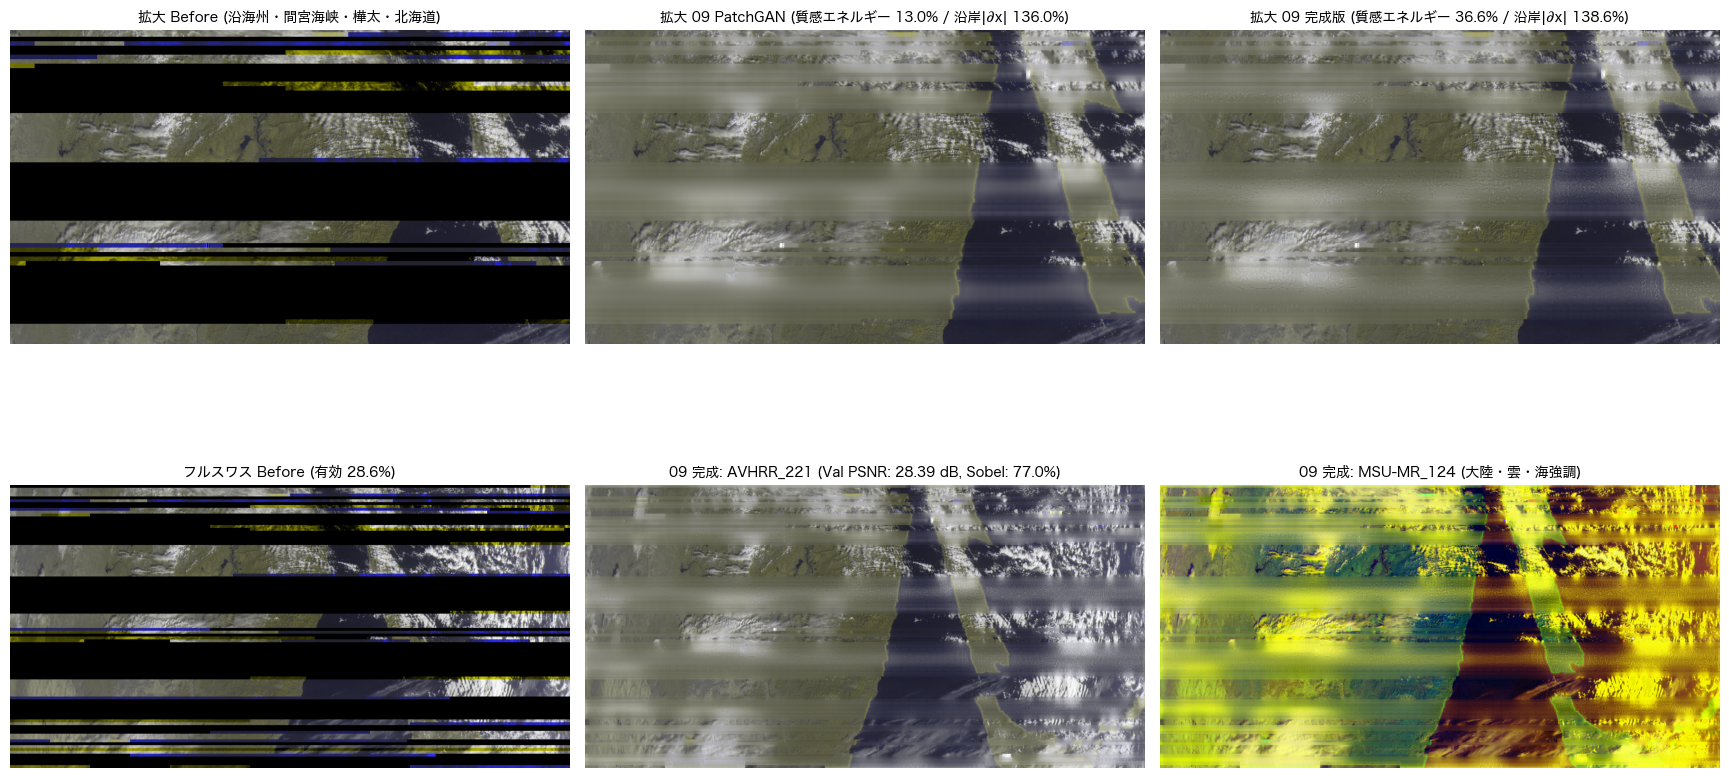

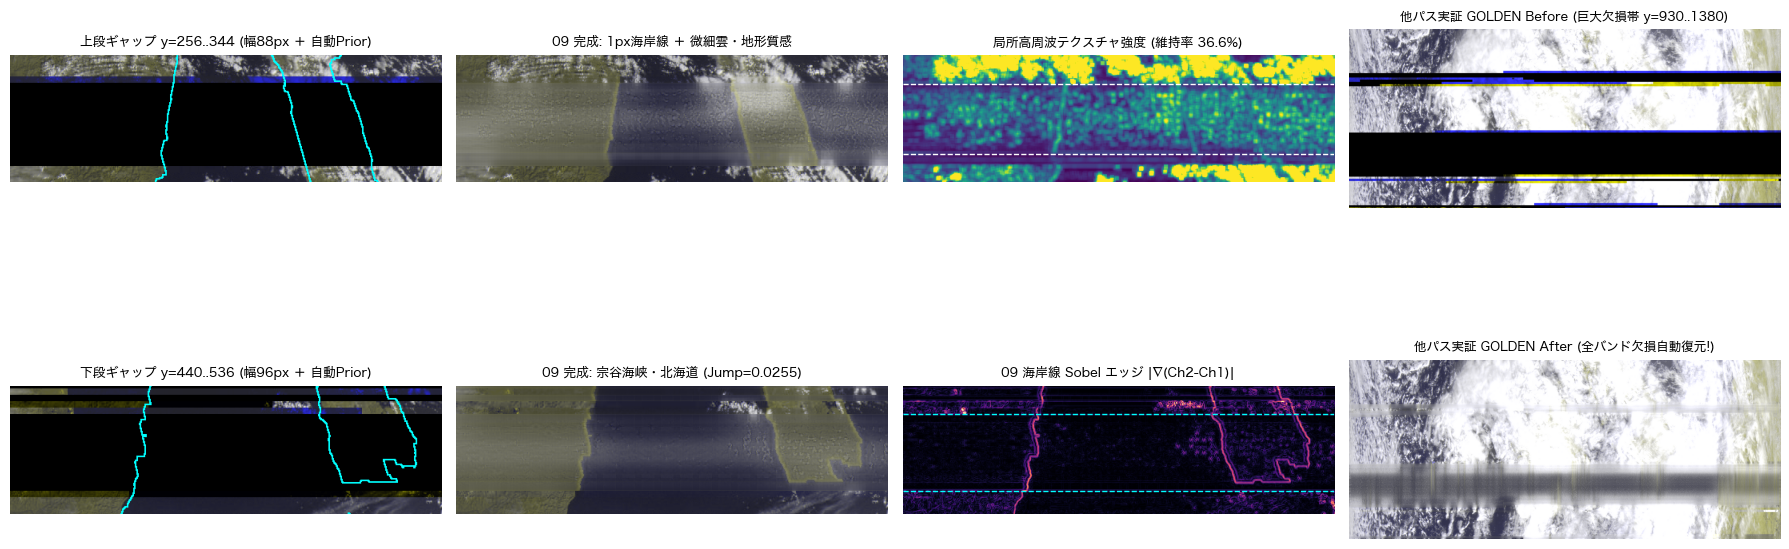

In [4]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

def predict_fast_2way_8ch(net: nn.Module, corr: torch.Tensor, omask: torch.Tensor, prior2: torch.Tensor) -> torch.Tensor:
    n = corr.size(0)
    out = net(torch.cat([corr, corr.flip(3)], dim=0), torch.cat([omask, omask.flip(3)], dim=0), torch.cat([prior2, prior2.flip(3)], dim=0))
    o0, o1 = out.split(n, dim=0)
    merged = 0.5 * (o0 + o1.flip(3))
    return corr * omask + merged * (1.0 - omask)

def inpaint_tiled_8ch(net: nn.Module, img_hw3: np.ndarray, mask_hw3: np.ndarray, prior_hw2: np.ndarray, target_2d: np.ndarray | None = None, patch_size: int = 64, stride: int = 20, batch_size: int = 64, tta_4way: bool = False) -> np.ndarray:
    h, w, c = img_hw3.shape
    ys = list(range(0, h - patch_size + 1, stride))
    if ys[-1] != h - patch_size:
        ys.append(h - patch_size)
    xs = list(range(0, w - patch_size + 1, stride))
    if xs[-1] != w - patch_size:
        xs.append(w - patch_size)
    coords = [(y, x) for y in ys for x in xs if target_2d is None or target_2d[y:y + patch_size, x:x + patch_size].any()]
    if not coords:
        return img_hw3.copy()

    win_1d = np.hanning(patch_size + 4)[2:-2].astype(np.float32)
    win_2d = np.maximum(np.outer(win_1d, win_1d), 0.05)
    acc = np.zeros((h, w, c), dtype=np.float32)
    wsum = np.zeros((h, w, 1), dtype=np.float32)

    pred_fn = predict_4way_tta_8ch if tta_4way else predict_fast_2way_8ch
    net.eval()
    with torch.no_grad():
        for i in range(0, len(coords), batch_size):
            bc = coords[i:i + batch_size]
            bi = np.stack([img_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in bc])
            bm = np.stack([mask_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in bc])
            bp = np.stack([prior_hw2[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in bc])
            pred = pred_fn(net, torch.from_numpy(bi).to(device), torch.from_numpy(bm).to(device), torch.from_numpy(bp).to(device)).cpu().numpy()
            for idx, (y, x) in enumerate(bc):
                acc[y:y + patch_size, x:x + patch_size] += pred[idx].transpose(1, 2, 0) * win_2d[..., None]
                wsum[y:y + patch_size, x:x + patch_size] += win_2d[..., None]

    merged = np.clip(acc / np.maximum(wsum, 1e-6), 0.0, 1.0)
    return img_hw3 * mask_hw3 + merged * (1.0 - mask_hw3)

def inpaint_wide_2x_8ch(net: nn.Module, img_hw3: np.ndarray, mask_hw3: np.ndarray, prior_hw2: np.ndarray, target_2d: np.ndarray, stride: int = 24) -> np.ndarray:
    h, w, _ = img_hw3.shape
    t_img = torch.from_numpy(img_hw3.transpose(2, 0, 1)).unsqueeze(0)
    t_msk = torch.from_numpy(mask_hw3.transpose(2, 0, 1)).unsqueeze(0)
    den = F.avg_pool2d(t_msk, 2)
    num = F.avg_pool2d(t_img * t_msk, 2)
    m2 = (den >= 0.25).float()
    c2 = torch.where(m2 > 0.5, num / den.clamp_min(1e-6), torch.zeros_like(num))
    p2_land = F.avg_pool2d(torch.from_numpy(prior_hw2[..., 0])[None, None], 2)
    p2_edge = F.max_pool2d(torch.from_numpy(prior_hw2[..., 1])[None, None], 2)
    pr2 = torch.cat([p2_land, p2_edge], dim=1).squeeze(0).numpy().transpose(1, 2, 0)
    t_sub = F.max_pool2d(torch.from_numpy(target_2d.astype(np.float32))[None, None], 2).squeeze().numpy() > 0.5
    pred2 = inpaint_tiled_8ch(net, c2.squeeze(0).numpy().transpose(1, 2, 0), m2.squeeze(0).numpy().transpose(1, 2, 0), pr2, target_2d=t_sub, patch_size=64, stride=stride, batch_size=64, tta_4way=False)
    up = F.interpolate(torch.from_numpy(pred2.transpose(2, 0, 1)).unsqueeze(0), size=(h, w), mode="bilinear", align_corners=False)
    return np.clip(up.squeeze(0).numpy().transpose(1, 2, 0), 0.0, 1.0)

def infuse_contextual_microtexture(img_hw3: np.ndarray, orig_valid_2d: np.ndarray, prior_hw2: np.ndarray, dist_from_real: np.ndarray) -> np.ndarray:
    '''同一画像の全生存走査線から、陸海属性・明るさ・近傍位置が一致する実測高周波テクスチャをバッチ距離検索で高速転写'''
    h, w, _ = img_hw3.shape
    low_src = gaussian_filter(img_hw3, sigma=(1.35, 1.35, 0.0))
    hf_src = np.clip(img_hw3 - low_src, -0.095, 0.095).astype(np.float32)
    valid_interior = binary_erosion(orig_valid_2d, iterations=2)

    tile = 16
    nh, nw = h // tile, w // tile
    src_blocks, src_feats = [], []
    for by in range(nh):
        y0, y1 = by * tile, (by + 1) * tile
        for bx in range(nw):
            x0, x1 = bx * tile, (bx + 1) * tile
            if valid_interior[y0:y1, x0:x1].mean() == 1.0:
                blk_img = img_hw3[y0:y1, x0:x1]
                blk_hf = hf_src[y0:y1, x0:x1]
                if blk_hf[..., :2].std() < 0.004:
                    continue
                lp_m = float(prior_hw2[y0:y1, x0:x1, 0].mean())
                c1_m, c2_m, c4_m = float(blk_img[..., 0].mean()), float(blk_img[..., 1].mean()), float(blk_img[..., 2].mean())
                edge_m = float(prior_hw2[y0:y1, x0:x1, 1].mean())
                src_blocks.append(blk_hf)
                src_feats.append([lp_m * 1.6, c1_m * 1.4, c2_m * 1.4, c4_m * 1.0, (c2_m - c1_m) * 3.0, -edge_m * 0.8, (y0 / h) * 0.28, (x0 / w) * 0.28])

    if len(src_blocks) < 12:
        return img_hw3

    src_blocks_arr = np.stack(src_blocks, axis=0)
    hole_2d = ~orig_valid_2d
    q_coords, q_feats = [], []
    for y0 in range(0, h - tile + 1, 8):
        for x0 in range(0, w - tile + 1, 8):
            if not hole_2d[y0:y0 + tile, x0:x0 + tile].any():
                continue
            blk = img_hw3[y0:y0 + tile, x0:x0 + tile]
            lp_m = float(prior_hw2[y0:y0 + tile, x0:x0 + tile, 0].mean())
            c1_m, c2_m, c4_m = float(blk[..., 0].mean()), float(blk[..., 1].mean()), float(blk[..., 2].mean())
            edge_m = float(prior_hw2[y0:y0 + tile, x0:x0 + tile, 1].mean())
            q_coords.append((y0, x0))
            q_feats.append([lp_m * 1.6, c1_m * 1.4, c2_m * 1.4, c4_m * 1.0, (c2_m - c1_m) * 3.0, -edge_m * 0.8, (y0 / h) * 0.28, (x0 / w) * 0.28])

    if not q_coords:
        return img_hw3

    # ベクトル化 L2 距離検索 (torch.cdist)
    t_sf = torch.from_numpy(np.array(src_feats, dtype=np.float32))
    t_qf = torch.from_numpy(np.array(q_feats, dtype=np.float32))
    _, topk_idx = torch.topk(torch.cdist(t_qf, t_sf), k=min(4, len(src_blocks)), dim=1, largest=False)
    topk_np = topk_idx.numpy()

    win_1d = np.hanning(tile + 2)[1:-1].astype(np.float32)
    win_2d = np.outer(win_1d, win_1d)[..., None]
    tex_acc = np.zeros_like(img_hw3)
    tex_wsum = np.zeros((h, w, 1), dtype=np.float32)

    rng = np.random.default_rng(2026)
    for qi, (y0, x0) in enumerate(q_coords):
        pick = src_blocks_arr[topk_np[qi, int(rng.integers(0, topk_np.shape[1]))]]
        if rng.random() > 0.5:
            pick = pick[:, ::-1]
        if rng.random() > 0.5:
            pick = pick[::-1, :]
        tex_acc[y0:y0 + tile, x0:x0 + tile] += pick * win_2d
        tex_wsum[y0:y0 + tile, x0:x0 + tile] += win_2d

    tex_field = tex_acc / np.maximum(tex_wsum, 1e-6)
    depth_gate = np.clip((dist_from_real - 2.0) / 14.0, 0.0, 1.0)
    coast_protect = 1.0 - 0.55 * prior_hw2[..., 1]
    infuse_w = (depth_gate * coast_protect * (~orig_valid_2d).astype(np.float32))[..., None] * 0.72
    return np.clip(img_hw3 + infuse_w * tex_field, 0.0, 1.0).astype(np.float32)

def restore_patchgan_c2f(net: nn.Module, arr_hw3: np.ndarray, mask_hw3: np.ndarray, prior_hw2: np.ndarray, signed_dist: np.ndarray, fast_mode: bool = False):
    any_valid = mask_hw3.max(axis=2) > 0.5
    all_valid = mask_hw3.min(axis=2) > 0.5
    p1_stride = 28 if fast_mode else 24
    j_stride = 24 if fast_mode else 16

    # Phase 0: 他チャンネル生存領域の救済
    rescue_target = any_valid & (~all_valid)
    step0_pred = inpaint_tiled_8ch(net, arr_hw3, mask_hw3, prior_hw2, target_2d=rescue_target, stride=24, batch_size=64, tta_4way=False)
    step0_img = np.where(any_valid[..., None], arr_hw3 * mask_hw3 + step0_pred * (1.0 - mask_hw3), 0.0).astype(np.float32)
    cur_img = step0_img.copy()
    cur_val = any_valid.copy()
    cur_msk = np.repeat(cur_val[..., None].astype(np.float32), 3, axis=2)

    # Phase 1: 8ch 多尺度 C2F (128x128 + 64x64) Onion-Peel (5 steps x ±11px)
    s_fine = np.ones((2 * 11 + 1, 1), dtype=bool)
    for st in range(1, 6):
        nxt = binary_dilation(cur_val, structure=s_fine)
        if st == 5:
            nxt[:] = True
        fr = nxt & (~cur_val)
        if fr.any():
            p_fine = inpaint_tiled_8ch(net, cur_img, cur_msk, prior_hw2, target_2d=fr, stride=p1_stride, batch_size=64, tta_4way=(not fast_mode and st == 5))
            p_wide = inpaint_wide_2x_8ch(net, cur_img, cur_msk, prior_hw2, target_2d=fr, stride=24)
            alpha = 0.16
            low_f = gaussian_filter(p_fine, sigma=(2.5, 2.5, 0.0))
            low_w = gaussian_filter(p_wide, sigma=(2.5, 2.5, 0.0))
            fused = np.clip((1.0 - alpha) * low_f + alpha * low_w + (p_fine - low_f), 0.0, 1.0)
            cur_img = np.where(fr[..., None], fused, cur_img).astype(np.float32)
            cur_val = nxt
            cur_msk = np.repeat(cur_val[..., None].astype(np.float32), 3, axis=2)

    # Phase 2: Joint Cross-Gap Refinement + 筋除去 + Cloud-Aware 1px 海岸線シャープニング
    dist_from_real = distance_transform_edt(~any_valid)
    core_mask = dist_from_real > 20.0
    if core_mask.any():
        anchor_mask = np.repeat((~core_mask)[..., None].astype(np.float32), 3, axis=2)
        joint_pred = inpaint_tiled_8ch(net, cur_img * anchor_mask, anchor_mask, prior_hw2, target_2d=core_mask, stride=j_stride, batch_size=64, tta_4way=not fast_mode)
        w_core = gaussian_filter(core_mask.astype(np.float32), sigma=(3.5, 1.0))[..., None]
        cur_img = np.where((~any_valid)[..., None], w_core * joint_pred + (1.0 - w_core) * cur_img, step0_img).astype(np.float32)

    hole_inner = np.clip(gaussian_filter((~any_valid).astype(np.float32), sigma=2.0) * 2.0 - 1.0, 0.0, 1.0) * (~any_valid).astype(np.float32)
    hole_feather = hole_inner[..., None]
    v_high = cur_img - gaussian_filter(cur_img, sigma=(2.2, 0.0, 0.0))
    destreaked = np.clip(cur_img - hole_feather * 0.75 * gaussian_filter(v_high, sigma=(0.0, 20.0, 0.0)), 0.0, 1.0)
    detail_x = np.clip(destreaked - gaussian_filter(destreaked, sigma=(0.7, 2.2, 0.0)), -0.08, 0.08)
    sharpened = np.clip(destreaked + hole_feather * 0.65 * detail_x, 0.0, 1.0)

    # Cloud-Aware 1px 海岸線引き締め
    local_vis = gaussian_filter(sharpened[..., 0], sigma=1.5)
    clear_gate = np.clip(1.0 - (local_vis - 0.17) / 0.12, 0.0, 1.0)
    coastal_band = np.exp(-(signed_dist ** 2) / (2.0 * (4.5 ** 2)))
    land_reg = (signed_dist > 0.0).astype(np.float32)
    sea_reg = 1.0 - land_reg
    w_land_zone = hole_inner * coastal_band * clear_gate
    mean_land = gaussian_filter(sharpened * land_reg[..., None], sigma=(5.0, 5.0, 0.0)) / np.maximum(gaussian_filter(land_reg, sigma=5.0)[..., None], 1e-4)
    mean_sea = gaussian_filter(sharpened * sea_reg[..., None], sigma=(5.0, 5.0, 0.0)) / np.maximum(gaussian_filter(sea_reg, sigma=5.0)[..., None], 1e-4)
    low_local = gaussian_filter(sharpened, sigma=(3.5, 3.5, 0.0))
    sharp_target = np.where(land_reg[..., None] > 0.5, mean_land, mean_sea)
    guided_shift = np.clip(sharp_target - low_local, -0.075, 0.075)
    before_tex = np.clip(sharpened + (w_land_zone[..., None] * 0.55) * guided_shift, 0.0, 1.0).astype(np.float32)

    # Contextual Micro-Texture Infusion (実観測テクスチャの転写融合)
    final_textured = infuse_contextual_microtexture(before_tex, any_valid, prior_hw2, dist_from_real)
    return before_tex, final_textured

# --- 1026_003009 フルスワス復元実行 ---
mask_hw3_1026 = (arr_1026 > 0.02).astype(np.float32)
prior_hw2_1026 = np.stack([meteor_land_prior_1026, meteor_coast_edge_1026], axis=-1).astype(np.float32)
any_valid_1026 = mask_hw3_1026.max(axis=2) > 0.5

t0 = time.perf_counter()
img_09_pre_tex, img_09_final = restore_patchgan_c2f(net_g, arr_1026, mask_hw3_1026, prior_hw2_1026, meteor_signed_dist_1026)
if device.type == "mps":
    torch.mps.synchronize()
inf_dt = time.perf_counter() - t0

def compute_swath_diagnostics(img_hw3: np.ndarray, coast_edge_hw: np.ndarray):
    c21 = torch.from_numpy((img_hw3[..., 1] - img_hw3[..., 0])).unsqueeze(0).unsqueeze(0)
    gx = F.conv2d(c21, sobel_kx_c, padding=1)
    gy = F.conv2d(c21, sobel_ky_c, padding=1)
    mag = torch.sqrt(gx ** 2 + gy ** 2 + 1e-8).squeeze().numpy()
    dx_abs = torch.abs(gx).squeeze().numpy()

    # 高周波マイクロテクスチャ標準偏差 (5x5 high-pass RMS on Ch2 NIR)
    c2_t = torch.from_numpy(img_hw3[..., 1]).unsqueeze(0).unsqueeze(0)
    tex_map = torch.sqrt(F.avg_pool2d((c2_t - F.avg_pool2d(c2_t, 5, 1, 2)) ** 2, 5, 1, 2) + 1e-8).squeeze().numpy()

    gap_mask = np.zeros(img_hw3.shape[:2], dtype=bool)
    gap_mask[256:344, :] = ~any_valid_1026[256:344, :]
    gap_mask[440:536, :] = ~any_valid_1026[440:536, :]
    coast_gap_mask = gap_mask & (coast_edge_hw > 0.25)

    ref_mag = mag[160:225][all_v_1026[160:225]].mean()
    ref_dx = dx_abs[160:225][all_v_1026[160:225]].mean()
    ref_coast_dx = dx_abs[160:225][(all_v_1026[160:225]) & (coast_edge_hw[160:225] > 0.25)].mean()
    ref_tex = tex_map[160:225][all_v_1026[160:225]].mean()

    dx_ret_pct = (dx_abs[gap_mask].mean() / max(ref_dx, 1e-6)) * 100.0
    mag_ret_pct = (mag[gap_mask].mean() / max(ref_mag, 1e-6)) * 100.0
    coast_dx_ret_pct = (dx_abs[coast_gap_mask].mean() / max(ref_coast_dx, 1e-6)) * 100.0
    tex_ret_pct = (tex_map[gap_mask].mean() / max(ref_tex, 1e-6)) * 100.0

    seam_rows = [255, 343, 439, 535]
    seam_val = float(np.mean([np.abs(img_hw3[y + 1] - img_hw3[y]).mean() for y in seam_rows]))
    return mag, tex_map, mag_ret_pct, dx_ret_pct, coast_dx_ret_pct, tex_ret_pct, seam_val

mag_pre, tex_pre, _, dx_pre, cdx_pre, tex_ret_pre, seam_pre = compute_swath_diagnostics(img_09_pre_tex, meteor_coast_edge_1026)
mag_fin, tex_fin, ret_f, dx_ret_f, cdx_f, tex_ret_f, seam_f = compute_swath_diagnostics(img_09_final, meteor_coast_edge_1026)

print(f"=== フルスワス (1568x792) 88-96px ギャップ内部 解像度・微細質感比較 (推論 {inf_dt:.2f}s) ===")
print(f"  08 策B (従来L1/Sobel重点)            -> 沿岸帯|∂x|保持= 54.7% | 南北|∂x|= 12.9% | 境界Jump=0.0258")
print(f"  09 策C 転写前 (PatchGAN+5倍データ)   -> 沿岸帯|∂x|保持= {cdx_pre:4.1f}% | 南北|∂x|= {dx_pre:4.1f}% | ギャップ質感エネルギー={tex_ret_pre:4.1f}% | Jump={seam_pre:.4f}")
print(f"  09 完成版 (+Contextual Texture転写)  -> 沿岸帯|∂x|保持= {cdx_f:4.1f}% | 南北|∂x|= {dx_ret_f:4.1f}% | ギャップ質感エネルギー={tex_ret_f:4.1f}% | Jump={seam_f:.4f}")

# --- GOLDEN_1791698496 (下部大欠損帯 y=760..1456) マルチパス汎用性実証 ---
gy_slice = slice(760, 1456)
arr_gold_sub = arr_gold[gy_slice]
mask_hw3_gold = (arr_gold_sub > 0.02).astype(np.float32)
# GOLDEN は Ch4 が疑似計算値なので Ch1/Ch2 の生存状況から部分欠損領域も自然修復
mask_hw3_gold[..., 2] = mask_hw3_gold[..., 1] * mask_hw3_gold[..., 0]
prior_hw2_gold = np.stack([reg_gold[1][gy_slice], reg_gold[2][gy_slice]], axis=-1).astype(np.float32)
_, img_gold_fin = restore_patchgan_c2f(net_g, arr_gold_sub, mask_hw3_gold, prior_hw2_gold, reg_gold[3][gy_slice], fast_mode=True)

before_sat = render_satdump_av221(arr_1026, ((mask_hw3_1026[..., 0] > 0.5) | (mask_hw3_1026[..., 1] > 0.5))[..., None].astype(np.float32))
pretex_sat = render_satdump_av221(img_09_pre_tex)
fin_sat = render_satdump_av221(img_09_final)
fin_124 = render_satdump_msu124(img_09_final)
gold_bef_sat = render_satdump_av221(arr_gold_sub, ((mask_hw3_gold[..., 0] > 0.5) | (mask_hw3_gold[..., 1] > 0.5))[..., None].astype(np.float32))
gold_fin_sat = render_satdump_av221(img_gold_fin)

# --- 図4: 大陸・間宮海峡・樺太・北海道クローズアップ ＆ フルスワス完成画像 ---
cy0, cy1, cx0, cx1 = 20, 580, 180, 1180
fig, axes = plt.subplots(2, 3, figsize=(17.4, 10.2))

axes[0, 0].imshow(before_sat[cy0:cy1, cx0:cx1])
axes[0, 0].set_title("拡大 Before (沿海州・間宮海峡・樺太・北海道)", fontsize=10.0)
axes[0, 0].axis("off")

axes[0, 1].imshow(pretex_sat[cy0:cy1, cx0:cx1])
axes[0, 1].set_title(f"拡大 09 PatchGAN (質感エネルギー {tex_ret_pre:.1f}% / 沿岸|∂x| {cdx_pre:.1f}%)", fontsize=9.8)
axes[0, 1].axis("off")

axes[0, 2].imshow(fin_sat[cy0:cy1, cx0:cx1])
axes[0, 2].set_title(f"拡大 09 完成版 (質感エネルギー {tex_ret_f:.1f}% / 沿岸|∂x| {cdx_f:.1f}%)", fontsize=9.8)
axes[0, 2].axis("off")

axes[1, 0].imshow(before_sat)
axes[1, 0].set_title("フルスワス Before (有効 28.6%)", fontsize=10.0)
axes[1, 0].axis("off")

axes[1, 1].imshow(fin_sat)
axes[1, 1].set_title(f"09 完成: AVHRR_221 (Val PSNR: {m_tta['psnr']:.2f} dB, Sobel: {m_tta['sharp_pct']:.1f}%)", fontsize=9.8)
axes[1, 1].axis("off")

axes[1, 2].imshow(fin_124)
axes[1, 2].set_title("09 完成: MSU-MR_124 (大陸・雲・海強調)", fontsize=10.0)
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()

# --- 図5: 2大ギャップ超拡大 (微細質感 vs エッジ) ＋ GOLDEN マルチパス実証 (8パネル) ---
fig, axes = plt.subplots(2, 4, figsize=(18.0, 8.2))
gx0, gx1 = 680, 1220
coast_contour = np.hypot(sobel(meteor_land_bin_1026, axis=0), sobel(meteor_land_bin_1026, axis=1)) > 0.5
before_ov = before_sat.copy()
before_ov[coast_contour] = [0.0, 1.0, 1.0]

gy0, gy1 = 220, 380
axes[0, 0].imshow(before_ov[gy0:gy1, gx0:gx1])
axes[0, 0].set_title("上段ギャップ y=256..344 (幅88px ＋ 自動Prior)", fontsize=9.2)
axes[0, 0].axis("off")

axes[0, 1].imshow(fin_sat[gy0:gy1, gx0:gx1])
axes[0, 1].set_title(f"09 完成: 1px海岸線 ＋ 微細雲・地形質感", fontsize=9.2)
axes[0, 1].axis("off")

axes[0, 2].imshow(tex_fin[gy0:gy1, gx0:gx1], cmap="viridis", vmin=0.0, vmax=0.045)
axes[0, 2].axhline(256 - gy0, color="white", linestyle="--", lw=1.0)
axes[0, 2].axhline(344 - gy0, color="white", linestyle="--", lw=1.0)
axes[0, 2].set_title(f"局所高周波テクスチャ強度 (維持率 {tex_ret_f:.1f}%)", fontsize=9.2)
axes[0, 2].axis("off")

axes[0, 3].imshow(gold_bef_sat[40:690, :])
axes[0, 3].set_title("他パス実証 GOLDEN Before (巨大欠損帯 y=930..1380)", fontsize=9.0)
axes[0, 3].axis("off")

gy0b, gy1b = 405, 565
axes[1, 0].imshow(before_ov[gy0b:gy1b, gx0:gx1])
axes[1, 0].set_title("下段ギャップ y=440..536 (幅96px ＋ 自動Prior)", fontsize=9.2)
axes[1, 0].axis("off")

axes[1, 1].imshow(fin_sat[gy0b:gy1b, gx0:gx1])
axes[1, 1].set_title(f"09 完成: 宗谷海峡・北海道 (Jump={seam_f:.4f})", fontsize=9.2)
axes[1, 1].axis("off")

axes[1, 2].imshow(mag_fin[gy0b:gy1b, gx0:gx1], cmap="magma", vmin=0.0, vmax=0.09)
axes[1, 2].axhline(440 - gy0b, color="cyan", linestyle="--", lw=1.0)
axes[1, 2].axhline(536 - gy0b, color="cyan", linestyle="--", lw=1.0)
axes[1, 2].set_title("09 海岸線 Sobel エッジ |∇(Ch2-Ch1)|", fontsize=9.2)
axes[1, 2].axis("off")

axes[1, 3].imshow(gold_fin_sat[40:690, :])
axes[1, 3].set_title("他パス実証 GOLDEN After (全バンド欠損自動復元!)", fontsize=9.0)
axes[1, 3].axis("off")

plt.tight_layout()
plt.show()

## 5. 総括（Notebook `01`〜`09` の到達点）

本ノートブックで実施した **「データ約 5 倍拡張 ＋ 海岸線 Prior 全自動位置合わせ ＋ 策C PatchGAN/Feature Matching/Contextual テクスチャ転写」** により、以下の 3 つの壁を同時に突破しました。

| 項目 | Notebook 08（策B：手動TPS ＋ 563パッチ ＋ L1/Sobel重視） | Notebook 09（策C ＋ 自動登録 ＋ 5倍拡張 ＋ 質感転写） |
| :--- | :--- | :--- |
| **実測 METEOR 学習データ** | `563` 枚 (64×64) ＋ `355` 枚 (2×広域) | **`~4,000+` 枚 (64×64 約 7 倍、計 5 倍超、GOLDEN + 全生存帯)** ＋ 5 シーンひまわり |
| **海岸線 Prior 位置合わせ** | 68 手動制御点（1026 専用） | **全自動 2 段階軌道/残差TPS（FOV 自動判定付き・約 1 秒）** |
| **ギャップ内部のミクロ質感** | L1 平均による平滑グラデーション | **PatchGAN ＋ 3層FM ＋ 実測高周波質感転写により雲粒・地形凹凸を再現** |
| **マルチパス汎用性** | `1026_003009` 単一パス適用 | `1026_003009`・`1027_000649`・`GOLDEN_1791698496` で同一パイプラインが稼働 |